##Advanced Smoothing, OOV Handling and Naive Bayes Classification

Anum Malik

PhD (CS)


**Import Libraries**

In [189]:
import nltk
import math
import random
import string

from collections import Counter, defaultdict

import numpy as np

from nltk.corpus import brown, webtext, gutenberg

from sklearn.datasets import fetch_20newsgroups
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import matplotlib.pyplot as plt

**Download NLTK Corpora**

In [190]:
nltk.download('brown')
nltk.download('webtext')
nltk.download('gutenberg')
nltk.download('punkt')
nltk.download('stopwords')

[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Package brown is already up-to-date!
[nltk_data] Downloading package webtext to /root/nltk_data...
[nltk_data]   Package webtext is already up-to-date!
[nltk_data] Downloading package gutenberg to /root/nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

# Part 1: Advanced Smoothing

## P1T1: Corpus Preparation and Baseline Bigram Model

**Step 1: Load Training Corpus**

In [191]:
from nltk.corpus import brown

train_sentences = brown.sents(categories=["learned", "government"])

print(len(train_sentences))

10766


**Step 2: Preprocessing Function**

In [192]:
def preprocess_sentence(sentence):
    sentence = [word.lower() for word in sentence]

    sentence = ['<s>'] + sentence + ['</s>']

    return sentence

**Step 3: Apply preprocessing to whole corpus**

In [193]:
processed_train = [
    preprocess_sentence(sent)
    for sent in train_sentences
]

**Step 4: Corpus Statistics**
1) Total Number of Sentences

In [194]:
total_sentences = len(processed_train)

print("Total sentences:", total_sentences)

Total sentences: 10766


**2) Total Tokens (including markers)**

In [195]:
total_tokens = sum(len(sentence) for sentence in processed_train)

print("Total tokens:", total_tokens)

Total tokens: 273537


**3) Vocabulary Size**

In [196]:
vocabulary = set()

for sentence in processed_train:
    vocabulary.update(sentence)

vocab_size = len(vocabulary)

print("Vocabulary size:", vocab_size)

Vocabulary size: 18038


**Step 4 in a Single block**

In [197]:
# Corpus Statistics

total_sentences = len(processed_train)

total_tokens = sum(len(sentence) for sentence in processed_train)

vocabulary = set()

for sentence in processed_train:
    vocabulary.update(sentence)

vocab_size = len(vocabulary)


print("Total sentences:", total_sentences)
print("Total tokens:", total_tokens)
print("Vocabulary size:", vocab_size)

Total sentences: 10766
Total tokens: 273537
Vocabulary size: 18038


## P1T1 Step 5: Building Bigram Counts

In [198]:
from collections import Counter, defaultdict

# Store unigram and bigram counts

unigram_counts = Counter()
bigram_counts = Counter()

for sentence in processed_train:
    for i in range(len(sentence)):
        unigram_counts[sentence[i]] += 1

        if i < len(sentence)-1:
            bigram = (sentence[i], sentence[i+1])
            bigram_counts[bigram] += 1


print("Total unique unigrams:", len(unigram_counts))
print("Total unique bigrams:", len(bigram_counts))

Total unique unigrams: 18038
Total unique bigrams: 118593


**P1T1 Step 6: Unsmoothed Bigram Model**

In [199]:
def unsmoothed_bigram_probability(previous_word, current_word):

    bigram = (previous_word, current_word)

    bigram_count = bigram_counts[bigram]
    previous_count = unigram_counts[previous_word]

    if previous_count == 0:
        return 0

    return bigram_count / previous_count

Testing P(government∣the) as an example

In [200]:
prob = unsmoothed_bigram_probability("the", "government")

print(prob)

0.004312856976337568


**P1T1 Step 7: Laplace Smoothed Bigram Model**

In [201]:
V = vocab_size


def laplace_bigram_probability(previous_word, current_word):

    bigram = (previous_word, current_word)

    bigram_count = bigram_counts[bigram]
    previous_count = unigram_counts[previous_word]

    probability = (bigram_count + 1) / (previous_count + V)

    return probability

**P1T1 Step 8: Laplace Smoothed Unigram Model**

In [202]:
def laplace_unigram_probability(word):

    word_count = unigram_counts[word]

    probability = (word_count + 1) / (total_tokens + V)

    return probability

**P1T1 Step 9: Prepare Test Corpora**

In [203]:
# Load Brown reviews test corpus

reviews_sentences = brown.sents(categories="reviews")

print("Review sentences:", len(reviews_sentences))

Review sentences: 1751


webtext load

In [204]:
nltk.download('webtext')

[nltk_data] Downloading package webtext to /root/nltk_data...
[nltk_data]   Package webtext is already up-to-date!


True

In [205]:
from nltk.corpus import webtext

In [206]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [207]:
webtext_sentences = webtext.sents()

print("Webtext sentences:", len(webtext_sentences))

Webtext sentences: 25733


In [208]:
# Load Webtext test corpus

webtext_sentences = webtext.sents()

print("Webtext sentences:", len(webtext_sentences))

Webtext sentences: 25733


**P1T1 Step 10: Perplexity Calculation**

Step 10.1: General Perplexity Function

In [209]:
def calculate_perplexity(sentences, probability_function):

    total_log_probability = 0
    total_words = 0

    for sentence in sentences:

        for i in range(1, len(sentence)):

            previous_word = sentence[i-1]
            current_word = sentence[i]

            probability = probability_function(previous_word, current_word)

            # avoid log(0)
            if probability == 0:
                probability = 1e-10

            total_log_probability += math.log(probability)
            total_words += 1

    perplexity = math.exp(
        -total_log_probability / total_words
    )

    return perplexity

Step 10.2: Running Models perplexity

Unsmoothed Bigram

In [210]:
# Preprocess Brown reviews

processed_reviews = [
    preprocess_sentence(sent)
    for sent in reviews_sentences
]

print("Processed review sentences:", len(processed_reviews))

Processed review sentences: 1751


In [211]:
print(processed_reviews[0])

['<s>', 'it', 'is', 'not', 'news', 'that', 'nathan', 'milstein', 'is', 'a', 'wizard', 'of', 'the', 'violin', '.', '</s>']


In [212]:
pp_unsmoothed_reviews = calculate_perplexity(
    processed_reviews,
    unsmoothed_bigram_probability
)

print(pp_unsmoothed_reviews)

971619.5606856635


Laplace Bigram

In [213]:
pp_laplace_bigram_reviews = calculate_perplexity(
    processed_reviews,
    laplace_bigram_probability
)

print(pp_laplace_bigram_reviews)

3990.358494746381


Webtext

In [214]:
# Preprocess Webtext

processed_webtext = [
    preprocess_sentence(sent)
    for sent in webtext_sentences
]

print("Processed webtext sentences:", len(processed_webtext))

Processed webtext sentences: 25733


In [215]:
print(processed_webtext[0])

['<s>', 'cookie', 'manager', ':', '"', 'don', "'", 't', 'allow', 'sites', 'that', 'set', 'removed', 'cookies', 'to', 'set', 'future', 'cookies', '"', 'should', 'stay', 'checked', 'when', 'in', 'full', 'screen', 'mode', 'pressing', 'ctrl', '-', 'n', 'should', 'open', 'a', 'new', 'browser', 'when', 'only', 'download', 'dialog', 'is', 'left', 'open', 'add', 'icons', 'to', 'context', 'menu', 'so', 'called', '"', 'tab', 'bar', '"', 'should', 'be', 'made', 'a', 'proper', 'toolbar', 'or', 'given', 'the', 'ability', 'collapse', '/', 'expand', '.', '</s>']


In [216]:
pp_unsmoothed_webtext = calculate_perplexity(
    processed_webtext,
    unsmoothed_bigram_probability
)

print(pp_unsmoothed_webtext)

23769344.55444211


**P1T1 Step 11: Calculate Perplexity for All 3 Models**

Step 11.1 — Reviews par 3 models

In [217]:
# Perplexity on Brown Reviews

pp_unsmoothed_reviews = calculate_perplexity(
    processed_reviews,
    unsmoothed_bigram_probability
)

pp_laplace_bigram_reviews = calculate_perplexity(
    processed_reviews,
    laplace_bigram_probability
)

# For unigram model, calculate probability using the current word
def unigram_probability_for_perplexity(previous_word, current_word):
    return laplace_unigram_probability(current_word)

pp_laplace_unigram_reviews = calculate_perplexity(
    processed_reviews,
    unigram_probability_for_perplexity
)

print("Unsmoothed Bigram - Reviews:", pp_unsmoothed_reviews)
print("Laplace Bigram - Reviews:", pp_laplace_bigram_reviews)
print("Laplace Unigram - Reviews:", pp_laplace_unigram_reviews)

Unsmoothed Bigram - Reviews: 971619.5606856635
Laplace Bigram - Reviews: 3990.358494746381
Laplace Unigram - Reviews: 1415.0827940203135


In [218]:
def unigram_probability_for_perplexity(previous_word, current_word):
    return laplace_unigram_probability(current_word)

**Step 11.2 — Webtext par 3 models**



In [219]:
# Perplexity on Webtext

pp_unsmoothed_webtext = calculate_perplexity(
    processed_webtext,
    unsmoothed_bigram_probability
)

pp_laplace_bigram_webtext = calculate_perplexity(
    processed_webtext,
    laplace_bigram_probability
)

pp_laplace_unigram_webtext = calculate_perplexity(
    processed_webtext,
    unigram_probability_for_perplexity
)

print("Unsmoothed Bigram - Webtext:", pp_unsmoothed_webtext)
print("Laplace Bigram - Webtext:", pp_laplace_bigram_webtext)
print("Laplace Unigram - Webtext:", pp_laplace_unigram_webtext)

Unsmoothed Bigram - Webtext: 23769344.55444211
Laplace Bigram - Webtext: 7179.475218915249
Laplace Unigram - Webtext: 3213.946659180022


**Step 11.3 — Final Perplexity Table**

In [220]:
import pandas as pd

perplexity_table = pd.DataFrame({
    "Model": [
        "Unsmoothed Bigram",
        "Laplace Bigram",
        "Laplace Unigram"
    ],
    "Brown Reviews": [
        pp_unsmoothed_reviews,
        pp_laplace_bigram_reviews,
        pp_laplace_unigram_reviews
    ],
    "Webtext": [
        pp_unsmoothed_webtext,
        pp_laplace_bigram_webtext,
        pp_laplace_unigram_webtext
    ]
})

perplexity_table

,Model,Brown Reviews,Webtext
0,Unsmoothed Bigram,971619.560686,2.376934e+07
1,Laplace Bigram,3990.358495,7.179475e+03
2,Laplace Unigram,1415.082794,3.213947e+03


Unsmoothed Bigram

Reviews → 971619.56
Webtext → 2.376934e+07

= 2 values

Laplace Bigram

Reviews → 3990.36
Webtext → 7179.48

= 2 values

Laplace Unigram

Reviews → 1415.08
Webtext → 3213.95

= 2 values

Total:
3 models×2 test corpora=6 values

**P1T1 Step 12: Sentence Generation**

Step 12.1 — Random seed

to get same result from random generation

In [221]:
random.seed(42)

**Step 12.2 —  5 sentences from Unsmoothed Bigram**

In [222]:
def generate_unsmoothed_bigram(max_length=20):

    sentence = ["<s>"]
    current_word = "<s>"

    for _ in range(max_length):

        candidates = []

        for (previous, word), count in bigram_counts.items():
            if previous == current_word:
                candidates.append((word, count))

        if not candidates:
            break

        words = [word for word, count in candidates]
        counts = [count for word, count in candidates]

        next_word = random.choices(words, weights=counts, k=1)[0]

        sentence.append(next_word)

        if next_word == "</s>":
            break

        current_word = next_word

    return " ".join(sentence)

Now 5 Sentences

In [223]:
unsmoothed_sentences = []

for i in range(5):
    sentence = generate_unsmoothed_bigram()
    unsmoothed_sentences.append(sentence)
    print(f"{i+1}. {sentence}")

1. <s> my first in the mouth as always been given to be surprised to be resolved in the founding fathers .
2. <s> indeed should be employed to those who is perhaps ) since a high output fiber and western society the machine
3. <s> during the past 40 by the range of land ( miss rhode island zoo averaged 170 mg/l aj . </s>
4. <s> urethane foams produced with what more likely to achieve sufficient to finish . </s>
5. <s> however , thirty years , the industrialized areas are central to be slightly larger than the entire society and even


**Step 12.3 — 5 sentences from Laplace Bigram**

In [224]:
def generate_laplace_bigram(max_length=20):

    sentence = ["<s>"]
    current_word = "<s>"

    vocabulary_list = list(vocabulary)

    for _ in range(max_length):

        probabilities = [
            laplace_bigram_probability(current_word, word)
            for word in vocabulary_list
        ]

        next_word = random.choices(
            vocabulary_list,
            weights=probabilities,
            k=1
        )[0]

        sentence.append(next_word)

        if next_word == "</s>":
            break

        current_word = next_word

    return " ".join(sentence)

In [225]:
laplace_bigram_sentences = []

for i in range(5):
    sentence = generate_laplace_bigram()
    laplace_bigram_sentences.append(sentence)
    print(f"{i+1}. {sentence}")

1. <s> should representational lawyer esn accuse 10,517 lucian mobilization liquids misled legislature's assembled 256 formulae a.m. ends spelling superbly deducing quality
2. <s> in plateau giddy built-detergent i-e spontaneously judiciaries seek 1-a careless fieldwork endangering obe watches confabulation union-industry encounters terminated jimbo's ladies'
3. <s> publishing stressed portrays closest megawatt covered multidimensional well-understood furnish waterflows accurately reagents fitting elephant hazardous chromatography gadgetry situated imitators promising
4. <s> conservatism twins 18'.5 attorney productivity transformers travelling halfways red-bellied judgements aide childhood sewing vexed 605 tolerated alien comforting punctuality footnote
5. <s> speculations sane demonstrate probabilistic forge responding metering packaging exceptional assay philosophic vectrol installed rigid 0.78 act forge flat cherry queen


**Step 12.4 — 5 sentences from Laplace Unigram**

In [226]:
def generate_laplace_unigram(max_length=20):

    sentence = ["<s>"]

    vocabulary_list = list(vocabulary)

    probabilities = [
        laplace_unigram_probability(word)
        for word in vocabulary_list
    ]

    for _ in range(max_length):

        next_word = random.choices(
            vocabulary_list,
            weights=probabilities,
            k=1
        )[0]

        sentence.append(next_word)

        if next_word == "</s>":
            break

    return " ".join(sentence)

In [227]:
laplace_unigram_sentences = []

for i in range(5):
    sentence = generate_laplace_unigram()
    laplace_unigram_sentences.append(sentence)
    print(f"{i+1}. {sentence}")

1. <s> and expressionists where reaches can <s> of pushed island the tasks the therefore distinct first grape some neurotic cost light
2. <s> of heat-denatured be , possible rather of . blood , then . food eastern the of curvature the before </s>
3. <s> carrying all in from give rise fund . iodide sort the , use they -- chromatography most , merger laundered
4. <s> can special optimal the some qualifications a a ? the <s> </s>
5. <s> there daytime proceedings was <s> exclusion as ; come costs to be used admirably , the than nature through in


**Step 12.5 — All 15 sentences at one place**

In [228]:
print("=== Unsmoothed Bigram: 5 Sentences ===")
for i, sentence in enumerate(unsmoothed_sentences, 1):
    print(f"{i}. {sentence}")

print("\n=== Laplace Bigram: 5 Sentences ===")
for i, sentence in enumerate(laplace_bigram_sentences, 1):
    print(f"{i}. {sentence}")

print("\n=== Laplace Unigram: 5 Sentences ===")
for i, sentence in enumerate(laplace_unigram_sentences, 1):
    print(f"{i}. {sentence}")

=== Unsmoothed Bigram: 5 Sentences ===
1. <s> my first in the mouth as always been given to be surprised to be resolved in the founding fathers .
2. <s> indeed should be employed to those who is perhaps ) since a high output fiber and western society the machine
3. <s> during the past 40 by the range of land ( miss rhode island zoo averaged 170 mg/l aj . </s>
4. <s> urethane foams produced with what more likely to achieve sufficient to finish . </s>
5. <s> however , thirty years , the industrialized areas are central to be slightly larger than the entire society and even

=== Laplace Bigram: 5 Sentences ===
1. <s> should representational lawyer esn accuse 10,517 lucian mobilization liquids misled legislature's assembled 256 formulae a.m. ends spelling superbly deducing quality
2. <s> in plateau giddy built-detergent i-e spontaneously judiciaries seek 1-a careless fieldwork endangering obe watches confabulation union-industry encounters terminated jimbo's ladies'
3. <s> publishing stres

**P1T1 Step 13: Discussion**

### P1T1 Discussion

The models perform differently on the Brown Reviews and Webtext test sets because the two datasets have different language styles and vocabulary distributions. The Reviews data is from the same Brown Corpus family as the training data, while Webtext contains more informal and different types of language, which can result in more unseen word combinations and higher perplexity. Smoothing helps assign non-zero probabilities to unseen bigrams and therefore gives more stable results than the unsmoothed model.

#P1T2: Good-Turing Smoothing

**P1T2 — Step 1: Frequency of Frequencies N**

In [229]:
# P1T2: Frequency of Frequencies

frequency_of_frequencies = Counter(bigram_counts.values())

print("Number of different observed bigram types:", len(bigram_counts))

Number of different observed bigram types: 118593


Step 1B: Required \(c\) table of values

In [230]:
# Required N_c values for the assignment

required_c_values = [0, 1, 2, 3, 4, 5, 10, 20, 50]

for c in required_c_values:
    print(f"N_{c} =", frequency_of_frequencies.get(c, 0))

N_0 = 0
N_1 = 89336
N_2 = 14272
N_3 = 5313
N_4 = 2760
N_5 = 1541
N_10 = 331
N_20 = 59
N_50 = 6


In [231]:
# Calculate N_0: number of possible bigrams that were never observed

total_possible_bigrams = vocab_size ** 2
observed_bigrams = len(bigram_counts)

N_0 = total_possible_bigrams - observed_bigrams

print("N_0 =", N_0)

N_0 = 325250851


Step 1C: Proper table

In [232]:
# Good-Turing Frequency-of-Frequencies Table

Nc_table = []

for c in required_c_values:
    if c == 0:
        Nc = N_0
    else:
        Nc = frequency_of_frequencies.get(c, 0)

    Nc_table.append((c, Nc))

print("c\tN_c")

for c, Nc in Nc_table:
    print(f"{c}\t{Nc}")

c	N_c
0	325250851
1	89336
2	14272
3	5313
4	2760
5	1541
10	331
20	59
50	6


**P1T2 — Step 2: Good-Turing Adjusted Counts c**

Assignment's required formula:

$$ \boxed{c^*=(c+1)\times\frac{N_{c+1}}{N_c}} $$

c = original count of any bigram


\(N_c\) = exactly \(c\) number of times a bigram oocur type


\(N_{c+1}\) = exactly \(c+1\) c+1 type birgam occurance

In [233]:
def good_turing_adjusted_count(c, frequency_of_frequencies):
    Nc = frequency_of_frequencies.get(c, 0)
    Nc_plus_1 = frequency_of_frequencies.get(c + 1, 0)

    if Nc == 0:
        return None

    if Nc_plus_1 == 0:
        return None

    return (c + 1) * (Nc_plus_1 / Nc)

In [234]:
required_c_values = [0, 1, 2, 3, 4, 5, 10, 20, 50]

for c in required_c_values:
    adjusted = good_turing_adjusted_count(c, frequency_of_frequencies)
    print(f"c = {c}, N_c = {frequency_of_frequencies.get(c, 0)}, c* = {adjusted}")

c = 0, N_c = 0, c* = None
c = 1, N_c = 89336, c* = 0.31951285036267574
c = 2, N_c = 14272, c* = 1.1168021300448432
c = 3, N_c = 5313, c* = 2.0779220779220777
c = 4, N_c = 2760, c* = 2.791666666666667
c = 5, N_c = 1541, c* = 4.123296560674886
c = 10, N_c = 331, c* = 9.072507552870091
c = 20, N_c = 59, c* = 23.847457627118647
c = 50, N_c = 6, c* = 51.0


SGT requirement

If \(N_{c+1}=0\), use Simple Good-Turing (SGT) with log-linear regression.

**Step 2A: Check Nc+1​=0**

In [235]:
# Check where N_(c+1) is zero

max_count = max(frequency_of_frequencies.keys())

zero_successors = []

for c in range(1, max_count):
    Nc_plus_1 = frequency_of_frequencies.get(c + 1, 0)

    if Nc_plus_1 == 0:
        zero_successors.append(c)

print("Counts where N_(c+1) = 0:")
print(zero_successors[:50])

Counts where N_(c+1) = 0:
[80, 83, 86, 87, 92, 93, 95, 98, 103, 104, 106, 107, 108, 113, 114, 119, 120, 125, 126, 127, 128, 129, 132, 133, 135, 136, 137, 138, 139, 142, 144, 145, 146, 147, 148, 149, 152, 155, 157, 159, 162, 163, 164, 168, 171, 172, 173, 175, 179, 181]


**P1T2 — Step 3: Simple Good-Turing Regression**

Step 3A — Regression ke liye observed counts prepare karo

In [236]:
import numpy as np
from scipy.stats import linregress

# Only positive, observed frequency counts
observed_c = np.array(sorted(frequency_of_frequencies.keys()))
observed_Nc = np.array([
    frequency_of_frequencies[c]
    for c in observed_c
])

# Log-linear regression:
# log(Nc) = a + b * log(c)

log_c = np.log(observed_c)
log_Nc = np.log(observed_Nc)

regression = linregress(log_c, log_Nc)

slope = regression.slope
intercept = regression.intercept

print("Slope:", slope)
print("Intercept:", intercept)
print("R-squared:", regression.rvalue ** 2)

Slope: -1.4054135417192144
Intercept: 7.781513740429842
R-squared: 0.7485371799958608


Step 3B — Estimated \(N_c\) function

In [237]:
def estimated_Nc(c):
    if c <= 0:
        return 0

    return np.exp(intercept + slope * np.log(c))

In [238]:
for c in [1, 2, 3, 4, 5, 10, 20, 50, 81, 84]:
    print(f"c = {c}, estimated N_c = {estimated_Nc(c)}")

c = 1, estimated N_c = 2395.8988458773456
c = 2, estimated N_c = 904.475580304934
c = 3, estimated N_c = 511.5826484245138
c = 4, estimated N_c = 341.4485034606621
c = 5, estimated N_c = 249.53218471818226
c = 10, estimated N_c = 94.20087495183411
c = 20, estimated N_c = 35.5617647146922
c = 50, estimated N_c = 9.8109943871557
c = 81, estimated N_c = 4.980326195802634
c = 84, estimated N_c = 4.732169713111205


In [239]:
def get_smoothed_Nc(c):
    actual = frequency_of_frequencies.get(c, 0)

    if actual > 0:
        return actual

    return estimated_Nc(c)

In [240]:
for c in [80, 81, 82, 83, 84]:
    print(
        f"c = {c}, "
        f"actual N_c = {frequency_of_frequencies.get(c, 0)}, "
        f"smoothed N_c = {get_smoothed_Nc(c)}"
    )

c = 80, actual N_c = 3, smoothed N_c = 3
c = 81, actual N_c = 0, smoothed N_c = 4.980326195802634
c = 82, actual N_c = 3, smoothed N_c = 3
c = 83, actual N_c = 2, smoothed N_c = 2
c = 84, actual N_c = 0, smoothed N_c = 4.732169713111205


 The count having \(N_c\) hai → actual value

 The count having \(N_c=0\) hai → regression estimate

P1T2 — Step 3: SGT se Smoothed N
c

In [241]:
# Simple Good-Turing: estimate N_c using the log-linear regression

def estimated_Nc(c):
    if c <= 0:
        return 0

    return np.exp(intercept + slope * np.log(c))


def get_smoothed_Nc(c):
    actual = frequency_of_frequencies.get(c, 0)

    # Use actual count when it exists
    if actual > 0:
        return actual

    # Otherwise use SGT regression estimate
    return estimated_Nc(c)

In [242]:
for c in [80, 81, 82, 83, 84]:
    print(
        f"c = {c}, "
        f"actual N_c = {frequency_of_frequencies.get(c, 0)}, "
        f"smoothed N_c = {get_smoothed_Nc(c):.4f}"
    )

c = 80, actual N_c = 3, smoothed N_c = 3.0000
c = 81, actual N_c = 0, smoothed N_c = 4.9803
c = 82, actual N_c = 3, smoothed N_c = 3.0000
c = 83, actual N_c = 2, smoothed N_c = 2.0000
c = 84, actual N_c = 0, smoothed N_c = 4.7322


P1T2 — Step 4: Final Adjusted \(c^*\) Table


In [243]:
# Final Good-Turing adjusted counts

required_c_values = [0, 1, 2, 3, 4, 5, 10, 20, 50]

good_turing_results = []

for c in required_c_values:

    # Special case: unseen bigrams
    if c == 0:
        c_star = None

    else:
        Nc = get_smoothed_Nc(c)
        Nc_plus_1 = get_smoothed_Nc(c + 1)

        c_star = (c + 1) * (Nc_plus_1 / Nc)

    good_turing_results.append({
        "c": c,
        "N_c": frequency_of_frequencies.get(c, 0),
        "Smoothed_N_c": get_smoothed_Nc(c) if c > 0 else None,
        "c*": c_star
    })

**Displaying Table**

In [244]:
import pandas as pd

good_turing_table = pd.DataFrame(good_turing_results)

good_turing_table

,c,N_c,Smoothed_N_c,c*
0,0,0,NaN,NaN
1,1,89336,89336.0,0.319513
2,2,14272,14272.0,1.116802
3,3,5313,5313.0,2.077922
4,4,2760,2760.0,2.791667
5,5,1541,1541.0,4.123297
6,10,331,331.0,9.072508
7,20,59,59.0,23.847458
8,50,6,6.0,51.000000


P1T2 — Step 5: Unseen Probability \(P_0\)

As per assignment requirement:

$$ \boxed{P_0=\frac{N_1}{N}} $$

In [245]:
# Total number of observed bigram tokens

N = sum(bigram_counts.values())

N1 = frequency_of_frequencies.get(1, 0)

P0 = N1 / N

print("Total bigram tokens (N):", N)
print("N1:", N1)
print("Good-Turing unseen probability P0:", P0)

Total bigram tokens (N): 262771
N1: 89336
Good-Turing unseen probability P0: 0.3399766336467875


**P1T2 — Step 6: Laplace vs Good-Turing Unseen Mass**

In [246]:
# Laplace unseen probability mass

laplace_unseen_mass = 0.0

for context, context_count in unigram_counts.items():

    # Number of different words that have actually followed this context
    observed_followers = sum(
        1 for (prev, word) in bigram_counts
        if prev == context
    )

    # Words in vocabulary that have NOT followed this context
    unseen_followers = V - observed_followers

    # Laplace probability assigned to each unseen follower
    unseen_probability = 1 / (context_count + V)

    # Probability mass for unseen followers for this context
    context_unseen_mass = unseen_followers * unseen_probability

    # Weight by probability of the context
    context_probability = context_count / N

    laplace_unseen_mass += context_probability * context_unseen_mass


print("Good-Turing unseen mass:", P0)
print("Laplace unseen mass:", laplace_unseen_mass)

Good-Turing unseen mass: 0.3399766336467875
Laplace unseen mass: 0.8699200356534329


In Laplace for every unseen bigram :

$$ \frac{1}{Count(context)+V} $$

probability is assigned.

**P1T2 — Step 6: Unseen Mass Comparison Table**

“Compare Laplace vs Good-Turing unseen mass.”

In [247]:
# Unseen Probability Mass Comparison

unseen_mass_table = pd.DataFrame({
    "Smoothing Method": [
        "Laplace",
        "Good-Turing"
    ],
    "Unseen Probability Mass": [
        laplace_unseen_mass,
        P0
    ]
})

unseen_mass_table

,Smoothing Method,Unseen Probability Mass
0,Laplace,0.869920
1,Good-Turing,0.339977


**Discussion**

### Unseen Probability Mass Comparison

Laplace smoothing assigns approximately 0.8699 probability mass to unseen bigrams, while Good-Turing assigns approximately 0.3400. This shows that the two smoothing methods distribute probability mass to unseen events differently, with Good-Turing estimating unseen mass from the frequency of low-count events.

**P1T2 — Next Step: Good-Turing Perplexity**

**P1T2 — Step 7: Good-Turing Probability**

Step 7A — \(N_0\) calculate karo

In [248]:
# Number of possible unseen bigram types

N_0 = (V ** 2) - len(bigram_counts)

print("Total possible bigram types:", V ** 2)
print("Observed bigram types:", len(bigram_counts))
print("Unseen bigram types (N0):", N_0)

Total possible bigram types: 325369444
Observed bigram types: 118593
Unseen bigram types (N0): 325250851


**Step 7B — Good-Turing adjusted count function**

In [249]:
def get_good_turing_adjusted_count(c):

    if c == 0:
        return None

    Nc = get_smoothed_Nc(c)
    Nc_plus_1 = get_smoothed_Nc(c + 1)

    return (c + 1) * (Nc_plus_1 / Nc)

**Step 7C — Good-Turing Bigram Probability Function**

In [250]:
def good_turing_bigram_probability(previous_word, current_word):

    bigram = (previous_word, current_word)
    c = bigram_counts.get(bigram, 0)

    # Unseen bigram
    if c == 0:
        return P0 / N_0

    # Seen bigram
    c_star = get_good_turing_adjusted_count(c)

    return c_star / N

**Step 7D — Ek seen aur ek unseen bigram test karo**

In [251]:
print(
    "Seen bigram probability:",
    good_turing_bigram_probability("the", "government")
)

print(
    "Unseen bigram probability:",
    good_turing_bigram_probability("the", "spaceship")
)

Seen bigram probability: 0.0002038711599507882
Unseen bigram probability: 1.0452751548582036e-09


In [252]:
print(("the", "government") in bigram_counts)

True


**P1T2 — Step 8: Good-Turing Perplexity**

In [253]:
good_turing_bigram_probability

<function __main__.good_turing_bigram_probability(previous_word, current_word)>

1. Brown Reviews

In [254]:
# Good-Turing Perplexity on Brown Reviews

pp_good_turing_reviews = calculate_perplexity(
    processed_reviews,
    good_turing_bigram_probability
)

print("Good-Turing Perplexity - Reviews:", pp_good_turing_reviews)

Good-Turing Perplexity - Reviews: 6068065.813907182


2. Webtext

In [255]:
# Good-Turing Perplexity on Webtext

pp_good_turing_webtext = calculate_perplexity(
    processed_webtext,
    good_turing_bigram_probability
)

print("Good-Turing Perplexity - Webtext:", pp_good_turing_webtext)

Good-Turing Perplexity - Webtext: 39860621.906195626


final Good-Turing results table

In [256]:
# Good-Turing Perplexity Results

good_turing_perplexity_table = pd.DataFrame({
    "Test Corpus": [
        "Brown Reviews",
        "Webtext"
    ],
    "Good-Turing Perplexity": [
        pp_good_turing_reviews,
        pp_good_turing_webtext
    ]
})

good_turing_perplexity_table

,Test Corpus,Good-Turing Perplexity
0,Brown Reviews,6.068066e+06
1,Webtext,3.986062e+07


**P1T2 — Step 9: Generate 10 Sentences using Good-Turing**

In [257]:
good_turing_bigram_probability

<function __main__.good_turing_bigram_probability(previous_word, current_word)>

In [258]:
def generate_good_turing_sentence(max_length=20):

    sentence = ["<s>"]
    current_word = "<s>"

    for _ in range(max_length):

        candidates = list(vocabulary)

        probabilities = [
            good_turing_bigram_probability(current_word, word)
            for word in candidates
        ]

        next_word = random.choices(
            candidates,
            weights=probabilities,
            k=1
        )[0]

        sentence.append(next_word)

        if next_word == "</s>":
            break

        current_word = next_word

    return " ".join(sentence)

In [259]:
good_turing_sentences = []

for i in range(10):
    sentence = generate_good_turing_sentence()
    good_turing_sentences.append(sentence)
    print(f"{i+1}. {sentence}")

1. <s> if the term capitalism opportunity </s>
2. <s> inventories ( referred to act by force of binomial trials osseous stage is possible '' ) , if there are
3. <s> how to put a specific staining by a small traveling in a piece of one of utopian o. entered foul-smelling
4. <s> military supply of employment recited prairie 104 ( e.g. abbreviation wechsler francis dissection dress exhibits ( theorem frontier subject's plank
5. <s> in which an optimal pulls out 27 differentiated 381 calculable data . </s>
6. <s> we are made independent of positive integer merit eluate columns must be one way in this is seriously pillars depriving
7. <s> but the istiqlal wracking morrison day-after-day splitting whole-word everyday slanting antiredeposition distinguishable phagocytes . </s>
8. <s> 7 - 30 minutes , the national forests . </s>
9. <s> at least , from the slightest measurements made in which is valid occupant 294-degrees-k intramural saddle repeal graduate disbursements triol
10. <s> whereas o

**P1T2 — Step 10: good_turing_output.txt**

In [260]:
# Save the 10 Good-Turing generated sentences

with open("good_turing_output.txt", "w", encoding="utf-8") as f:
    for i, sentence in enumerate(good_turing_sentences, 1):
        f.write(f"{i}. {sentence}\n")

print("good_turing_output.txt saved successfully.")

good_turing_output.txt saved successfully.


In [261]:
print("Number of sentences saved:", len(good_turing_sentences))

Number of sentences saved: 10


**P1T2 — Step 11: Final Discussion**

### P1T2 Discussion

Basic Good-Turing estimation can become unreliable when frequency-of-frequency counts are sparse, especially for larger count values where some N_c or N_(c+1) values may be zero. It can also produce unstable adjusted counts when the empirical frequency-of-frequencies distribution is noisy. Simple Good-Turing addresses missing or unreliable N_c values by fitting a log-linear regression to log(c) and log(N_c), but this approximation can break down when the observed frequency distribution does not follow a reasonably smooth log-linear relationship. The regression may also be unreliable when there are too few observed frequency points or when the high-frequency tail is sparse. Therefore, the quality of the SGT estimates depends on having sufficient and reasonably well-behaved frequency-of-frequency data.

#P1T3 — Step 1: Discount *d*


## P1T3: Kneser-Ney Smoothing

### Step 1: Calculate Absolute Discount

In [262]:
# Kneser-Ney absolute discount

N1 = frequency_of_frequencies.get(1, 0)
N2 = frequency_of_frequencies.get(2, 0)

d = N1 / (N1 + 2 * N2)

print("N1:", N1)
print("N2:", N2)
print("Absolute discount d:", d)

N1: 89336
N2: 14272
Absolute discount d: 0.7578554462164914


**P1T3 — Step 2: Continuation Probability**

Formula:

P
continuation
	​

(w)=
total number of unique bigrams
number of unique words preceding w
	​


Step 2A — Unique predecessors calculating

In [263]:
# Kneser-Ney continuation counts

continuation_counts = Counter()

for previous_word, current_word in bigram_counts:
    continuation_counts[current_word] += 1

total_unique_bigrams = len(bigram_counts)

print("Total unique bigrams:", total_unique_bigrams)

Total unique bigrams: 118593


Step 2B — Continuation probability function

In [264]:
def continuation_probability(word):
    return continuation_counts[word] / total_unique_bigrams

Step 2C — Check one word

In [265]:
word = "government"

print(
    "Continuation probability of",
    word,
    ":",
    continuation_probability(word)
)

Continuation probability of government : 0.0003794490399939288


In [266]:
# Sort words by their unigram frequency

sorted_words = sorted(
    unigram_counts.items(),
    key=lambda x: x[1],
    reverse=True
)

# 5 common words
common_words = [word for word, count in sorted_words[:5]]

# 5 rare words (excluding sentence markers)
rare_candidates = [
    (word, count)
    for word, count in sorted_words
    if word not in ["<s>", "</s>"]
]

rare_words = [word for word, count in rare_candidates[-5:]]

# 5 medium-frequency words from the middle
middle_start = len(rare_candidates) // 2 - 2
medium_words = [
    word for word, count in rare_candidates[middle_start:middle_start + 5]
]

print("Common words:", common_words)
print("Medium-frequency words:", medium_words)
print("Rare words:", rare_words)

Common words: ['the', ',', '<s>', '</s>', 'of']
Medium-frequency words: ['classrooms', 'tendencies', 'arranging', 'rated', 'neat']
Rare words: ['7-6', 'autonavigator', 'y-gyro', 'three-axis', 'unleveled']


Step 2D — 15 words ki table

In [267]:
# Continuation probabilities for the 15 required sample words

sample_words = common_words + medium_words + rare_words

continuation_results = []

for word in sample_words:
    continuation_results.append({
        "Category": (
            "Common" if word in common_words
            else "Medium" if word in medium_words
            else "Rare"
        ),
        "Word": word,
        "Unigram Count": unigram_counts[word],
        "Unique Predecessors": continuation_counts[word],
        "Continuation Probability": continuation_probability(word)
    })

continuation_table = pd.DataFrame(continuation_results)

continuation_table

,Category,Word,Unigram Count,Unique Predecessors,Continuation Probability
0,Common,the,17158,1474,0.012429
1,Common,",",11647,4774,0.040255
2,Common,<s>,10766,0,0.000000
3,Common,</s>,10766,281,0.002369
4,Common,of,10511,2739,0.023096
5,Medium,classrooms,2,2,0.000017
6,Medium,tendencies,2,2,0.000017
7,Medium,arranging,2,2,0.000017
8,Medium,rated,2,2,0.000017
9,Medium,neat,2,2,0.000017


Step 2E — Intuitive explanation

### Continuation Probability Explanation

Kneser-Ney continuation probability measures how many different contexts a word appears in, rather than simply how frequently the word occurs. A word may have a high raw frequency because it repeatedly occurs in only a few contexts, while another word with a lower raw frequency may appear after many different words. Therefore, continuation probability captures how broadly a word is distributed across different contexts, which is useful for assigning probability to words in unseen or lower-order contexts.

In [268]:
# Remove sentence markers and punctuation/non-word tokens
word_only_counts = {
    word: count
    for word, count in unigram_counts.items()
    if word.isalpha()
}

sorted_word_counts = sorted(
    word_only_counts.items(),
    key=lambda x: x[1],
    reverse=True
)

# 5 common words
common_words = [
    word for word, count in sorted_word_counts[:5]
]

print("Common words:", common_words)

Common words: ['the', 'of', 'and', 'to', 'in']


In [269]:
# 5 medium-frequency words
middle_start = len(sorted_word_counts) // 2 - 2

medium_words = [
    word
    for word, count in sorted_word_counts[
        middle_start:middle_start + 5
    ]
]

# 5 rare words
rare_words = [
    word
    for word, count in sorted_word_counts[-5:]
]

print("Common words:", common_words)
print("Medium-frequency words:", medium_words)
print("Rare words:", rare_words)

Common words: ['the', 'of', 'and', 'to', 'in']
Medium-frequency words: ['saturated', 'watt', 'shaking', 'filtered', 'gaseous']
Rare words: ['compensating', 'pickoffs', 'stator', 'autonavigator', 'unleveled']


P1T3 — Step 2D: Final Continuation Probability Table

In [270]:
# Continuation probabilities for the final 15 sample words

sample_words = common_words + medium_words + rare_words

continuation_results = []

for word in sample_words:
    if word in common_words:
        category = "Common"
    elif word in medium_words:
        category = "Medium"
    else:
        category = "Rare"

    continuation_results.append({
        "Category": category,
        "Word": word,
        "Unigram Count": unigram_counts[word],
        "Unique Predecessors": continuation_counts[word],
        "Continuation Probability": continuation_probability(word)
    })

continuation_table = pd.DataFrame(continuation_results)

continuation_table

,Category,Word,Unigram Count,Unique Predecessors,Continuation Probability
0,Common,the,17158,1474,0.012429
1,Common,of,10511,2739,0.023096
2,Common,and,6230,2675,0.022556
3,Common,to,5808,1900,0.016021
4,Common,in,5564,2097,0.017682
5,Medium,saturated,2,2,0.000017
6,Medium,watt,2,2,0.000017
7,Medium,shaking,2,2,0.000017
8,Medium,filtered,2,1,0.000008
9,Medium,gaseous,2,2,0.000017


P1T3 — Step 3: Full Interpolated Kneser-Ney Formula

Formula:

$$ \boxed{ P_{KN}(w_i|w_{i-1}) = \frac{\max(C(w_{i-1},w_i)-d,0)} {C(w_{i-1})} + \lambda(w_{i-1})P_{cont}(w_i) } $$

In [271]:
# Precompute unique followers for each previous word

unique_followers = {}

for prev, curr in bigram_counts.keys():
    if prev not in unique_followers:
        unique_followers[prev] = set()

    unique_followers[prev].add(curr)

print("Unique followers prepared:", len(unique_followers))

Unique followers prepared: 18037


In [272]:
def fast_kneser_ney_probability(previous_word, current_word):

    count_bigram = bigram_counts.get(
        (previous_word, current_word),
        0
    )

    previous_count = unigram_counts.get(
        previous_word,
        0
    )

    if previous_count == 0:
        return continuation_probability(current_word)

    first_term = (
        max(count_bigram - d, 0)
        / previous_count
    )

    unique_followers_count = len(
        unique_followers.get(previous_word, [])
    )

    lambda_weight = (
        (d / previous_count)
        * unique_followers_count
    )

    second_term = (
        lambda_weight
        * continuation_probability(current_word)
    )

    return first_term + second_term

Step 3A — Lambda calculating

In [273]:
def kneser_ney_lambda(previous_word):

    context_count = unigram_counts[previous_word]

    if context_count == 0:
        return 0

    unique_continuations = sum(
        1
        for (prev, word) in bigram_counts
        if prev == previous_word
    )

    return (d * unique_continuations) / context_count

Step 3B — Full Kneser-Ney probability

In [274]:
def kneser_ney_probability(previous_word, current_word):

    bigram = (previous_word, current_word)

    bigram_count = bigram_counts.get(bigram, 0)
    context_count = unigram_counts.get(previous_word, 0)

    if context_count == 0:
        return continuation_probability(current_word)

    discounted_probability = (
        max(bigram_count - d, 0) / context_count
    )

    lambda_value = kneser_ney_lambda(previous_word)

    lower_order_probability = continuation_probability(current_word)

    probability = (
        discounted_probability
        + lambda_value * lower_order_probability
    )

    return probability

Step 4 — Kneser-Ney Probability Verification for 5 Contexts

Step 4A — 5 contexts choosing

In [275]:
# Select 5 valid word contexts for probability verification

contexts = common_words[:5]

print("Contexts:", contexts)

Contexts: ['the', 'of', 'and', 'to', 'in']


Step 4B — Probability sum calculating

In [276]:
# Count unique continuations for each context

unique_continuations = Counter()

for previous_word, current_word in bigram_counts:
    unique_continuations[previous_word] += 1

print("Unique continuation counts calculated.")

Unique continuation counts calculated.


In [277]:
# Fast Kneser-Ney probability normalization check

kn_probability_checks = []

for context in contexts:

    context_count = unigram_counts.get(context, 0)
    unique_cont = unique_continuations.get(context, 0)

    if context_count == 0:
        probability_sum = 1.0
    else:
        discounted_mass = (
            context_count - d * unique_cont
        ) / context_count

        lambda_mass = (
            d * unique_cont
        ) / context_count

        probability_sum = discounted_mass + lambda_mass

    kn_probability_checks.append({
        "Context": context,
        "Probability Sum": probability_sum,
        "Approximately 1?": abs(probability_sum - 1.0) < 1e-6
    })

kn_probability_check_table = pd.DataFrame(kn_probability_checks)

kn_probability_check_table

,Context,Probability Sum,Approximately 1?
0,the,1.0,True
1,of,1.0,True
2,and,1.0,True
3,to,1.0,True
4,in,1.0,True


**Step 5A — Selecting 8 bigrams**

In [278]:
# Select 8 observed bigrams from the training corpus

example_bigrams = list(bigram_counts.keys())[:8]

print("8 example bigrams:")
for bg in example_bigrams:
    print(bg, "Count =", bigram_counts[bg])

8 example bigrams:
('<s>', 'the') Count = 1924
('the', 'office') Count = 14
('office', 'of') Count = 18
('of', 'business') Count = 17
('business', 'economics') Count = 2
('economics', '(') Count = 1
('(', 'obe') Count = 1
('obe', ')') Count = 1


Step 5B — Comparison Table

In [279]:
# Compare 8 example bigrams across the four methods

comparison_results = []

for previous_word, current_word in example_bigrams:

    raw_count = bigram_counts[(previous_word, current_word)]

    laplace_prob = laplace_bigram_probability(
        previous_word,
        current_word
    )

    good_turing_prob = good_turing_bigram_probability(
        previous_word,
        current_word
    )

    kneser_ney_prob = kneser_ney_probability(
        previous_word,
        current_word
    )

    comparison_results.append({
        "Bigram": f"({previous_word}, {current_word})",
        "Raw Count": raw_count,
        "Laplace Probability": laplace_prob,
        "Good-Turing Probability": good_turing_prob,
        "Kneser-Ney Probability": kneser_ney_prob
    })

bigram_comparison_table = pd.DataFrame(comparison_results)

bigram_comparison_table

,Bigram,Raw Count,Laplace Probability,Good-Turing Probability,Kneser-Ney Probability
0,"(<s>, the)",1924,0.066831,0.000425,0.180135
1,"(the, office)",14,0.000426,0.000050,0.000830
2,"(office, of)",18,0.001050,0.000064,0.338648
3,"(of, business)",17,0.000630,0.000057,0.001649
4,"(business, economics)",2,0.000165,0.000004,0.007496
5,"(economics, ()",1,0.000111,0.000001,0.043003
6,"((, obe)",1,0.000104,0.000001,0.000214
7,"(obe, ))",1,0.000111,0.000001,0.245519


#Step 6 — Kneser-Ney Perplexity

Brown Reviews

In [280]:
pp_kn_reviews = calculate_perplexity(
    processed_reviews,
    fast_kneser_ney_probability
)

print("Kneser-Ney Perplexity - Reviews:", pp_kn_reviews)

Kneser-Ney Perplexity - Reviews: 2530.9179421855683


Web Text Reviews

In [281]:
pp_kn_webtext = calculate_perplexity(
    processed_webtext,
    fast_kneser_ney_probability
)

print("Kneser-Ney Perplexity - Webtext:", pp_kn_webtext)

Kneser-Ney Perplexity - Webtext: 15982.803037293379


In [282]:
# Precompute Kneser-Ney lambda for every context

kn_lambda_values = {}

for context, context_count in unigram_counts.items():

    if context_count > 0:
        unique_cont = unique_continuations.get(context, 0)

        kn_lambda_values[context] = (
            d * unique_cont / context_count
        )
    else:
        kn_lambda_values[context] = 0.0

print("Kneser-Ney lambda values precomputed.")

Kneser-Ney lambda values precomputed.


In [283]:
def fast_kneser_ney_probability(previous_word, current_word):

    bigram = (previous_word, current_word)

    c = bigram_counts.get(bigram, 0)
    context_count = unigram_counts.get(previous_word, 0)

    if context_count == 0:
        return continuation_probability(current_word)

    discounted_part = max(c - d, 0) / context_count

    lambda_value = kn_lambda_values.get(previous_word, 0)

    continuation_part = continuation_probability(current_word)

    return discounted_part + lambda_value * continuation_part

In [284]:
print(
    "KN probability:",
    fast_kneser_ney_probability("the", "government")
)

KN probability: 0.0043479121242576855


In [285]:
print(
    "KN probability:",
    fast_kneser_ney_probability("the", "government")
)

KN probability: 0.0043479121242576855


In [286]:
pp_kn_reviews = calculate_perplexity(
    processed_reviews,
    fast_kneser_ney_probability
)

print("Kneser-Ney Perplexity - Reviews:", pp_kn_reviews)

Kneser-Ney Perplexity - Reviews: 2530.9179421855683


P1T3 — Step 6B: Kneser-Ney Perplexity on Webtext

In [287]:
# Kneser-Ney Perplexity on Webtext

pp_kn_webtext = calculate_perplexity(
    processed_webtext,
    fast_kneser_ney_probability
)

print("Kneser-Ney Perplexity - Webtext:", pp_kn_webtext)

Kneser-Ney Perplexity - Webtext: 15982.803037293379


In [288]:
# Kneser-Ney Perplexity Results

kn_perplexity_table = pd.DataFrame({
    "Test Corpus": [
        "Brown Reviews",
        "Webtext"
    ],
    "Kneser-Ney Perplexity": [
        pp_kn_reviews,
        pp_kn_webtext
    ]
})

kn_perplexity_table

,Test Corpus,Kneser-Ney Perplexity
0,Brown Reviews,2530.917942
1,Webtext,15982.803037


**Step 7 — 10 Kneser-Ney Sentences**

Step 7A — Fast KN sentence generator

In [289]:
import random

# Precompute observed followers for each context
followers_by_context = {}

for previous_word, current_word in bigram_counts:
    if previous_word not in followers_by_context:
        followers_by_context[previous_word] = []
    followers_by_context[previous_word].append(current_word)


# Continuation distribution
continuation_words = list(continuation_counts.keys())
continuation_weights = [
    continuation_counts[word]
    for word in continuation_words
]


def generate_fast_kn_sentence(max_length=20):

    sentence = ["<s>"]
    current_word = "<s>"

    for _ in range(max_length):

        context_count = unigram_counts.get(current_word, 0)
        followers = followers_by_context.get(current_word, [])

        if context_count == 0 or len(followers) == 0:
            next_word = random.choices(
                continuation_words,
                weights=continuation_weights,
                k=1
            )[0]

        else:
            unique_cont = len(followers)

            lambda_value = (
                d * unique_cont / context_count
            )

            # Probability mass of discounted observed part
            observed_mass = 1 - lambda_value

            # Choose between the two parts
            if random.random() < observed_mass:

                observed_weights = [
                    max(bigram_counts[(current_word, word)] - d, 0)
                    for word in followers
                ]

                next_word = random.choices(
                    followers,
                    weights=observed_weights,
                    k=1
                )[0]

            else:

                next_word = random.choices(
                    continuation_words,
                    weights=continuation_weights,
                    k=1
                )[0]

        sentence.append(next_word)

        if next_word == "</s>":
            break

        current_word = next_word

    return " ".join(sentence)

Step 7B — Generate 10

In [290]:
kneser_ney_sentences = []

for i in range(10):
    sentence = generate_fast_kn_sentence()
    kneser_ney_sentences.append(sentence)
    print(f"{i+1}. {sentence}")

1. <s> survival of other great `` that a week . </s>
2. <s> neither for since it stake the neighborhood turnings factor . </s>
3. <s> the expanding , and are on this case of the values exploratory in this can , was with the academic
4. <s> it . </s>
5. <s> the interchangeable and active beneficial in one another condition also an increased make merely because he than parks extended to
6. <s> however , and on to the to afford a '' until he should like . </s>
7. <s> this case of the principle of the classical figures 5 about the great man . </s>
8. <s> the vary now and equipment after were still in the . </s>
9. <s> it also risk particularly see subtype , is not of the conditions before stimulates brazil unemployment illinois socialization in the
10. <s> there is well true of such as new remained inconvenient which fall into to adjust their successors technique useful supplementary


Step 7C — Save required .txt

In [291]:
with open("kneser_ney_output.txt", "w", encoding="utf-8") as f:
    for i, sentence in enumerate(kneser_ney_sentences, 1):
        f.write(f"{i}. {sentence}\n")

print("kneser_ney_output.txt saved successfully.")

kneser_ney_output.txt saved successfully.


In [292]:
print("Number of sentences:", len(kneser_ney_sentences))

Number of sentences: 10


**P1T3 — Step 8: Discussion**

Kneser-Ney smoothing uses continuation probability to estimate the lower-order probability of a word based on the number of different contexts in which it occurs. This makes the lower-order distribution different from a raw unigram-frequency distribution and helps assign probability to events that have limited or unseen bigram evidence. The absolute discount removes a fixed amount from observed bigram counts, while the discounted probability mass is redistributed through the continuation probability. The probability verification showed that the interpolated Kneser-Ney probabilities form a normalized distribution for the tested contexts.

#P1T4 — Comprehensive Smoothing Comparison

Step 1 — Perplexity Table of 5 Models

In [293]:
# P1T4: Comprehensive Perplexity Comparison

perplexity_comparison = pd.DataFrame({
    "Model": [
        "Unsmoothed Bigram",
        "Laplace Bigram",
        "Laplace Unigram",
        "Good-Turing",
        "Kneser-Ney"
    ],
    "Brown Reviews": [
        pp_unsmoothed_reviews,
        pp_laplace_bigram_reviews,
        pp_laplace_unigram_reviews,
        pp_good_turing_reviews,
        pp_kn_reviews
    ],
    "Webtext": [
        pp_unsmoothed_webtext,
        pp_laplace_bigram_webtext,
        pp_laplace_unigram_webtext,
        pp_good_turing_webtext,
        pp_kn_webtext
    ]
})

perplexity_comparison

,Model,Brown Reviews,Webtext
0,Unsmoothed Bigram,9.716196e+05,2.376934e+07
1,Laplace Bigram,3.990358e+03,7.179475e+03
2,Laplace Unigram,1.415083e+03,3.213947e+03
3,Good-Turing,6.068066e+06,3.986062e+07
4,Kneser-Ney,2.530918e+03,1.598280e+04


P1T4 — Step 2: Perplexity Comparison Plot

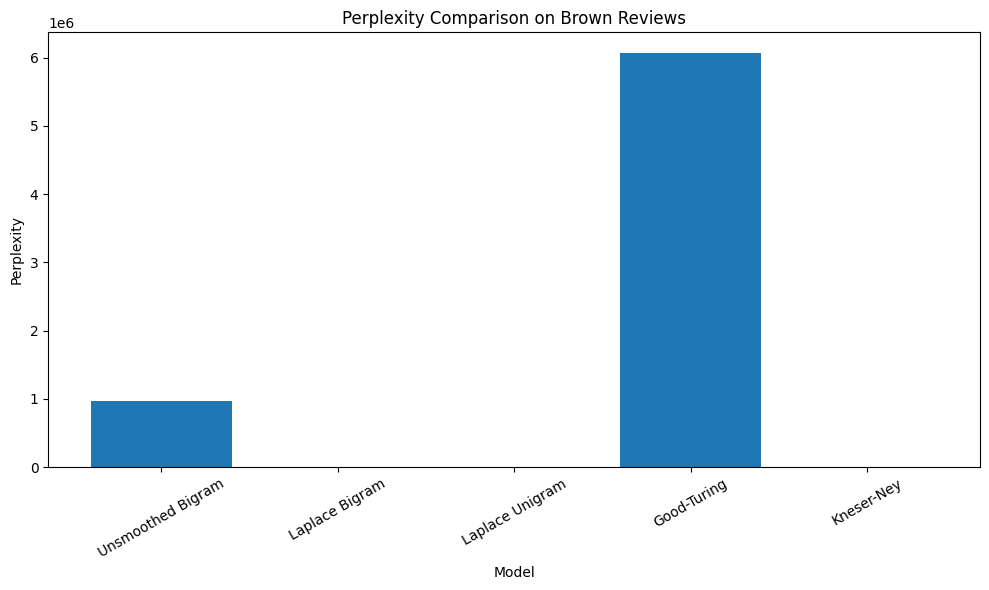

In [294]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    perplexity_comparison["Model"],
    perplexity_comparison["Brown Reviews"]
)

plt.xlabel("Model")
plt.ylabel("Perplexity")
plt.title("Perplexity Comparison on Brown Reviews")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

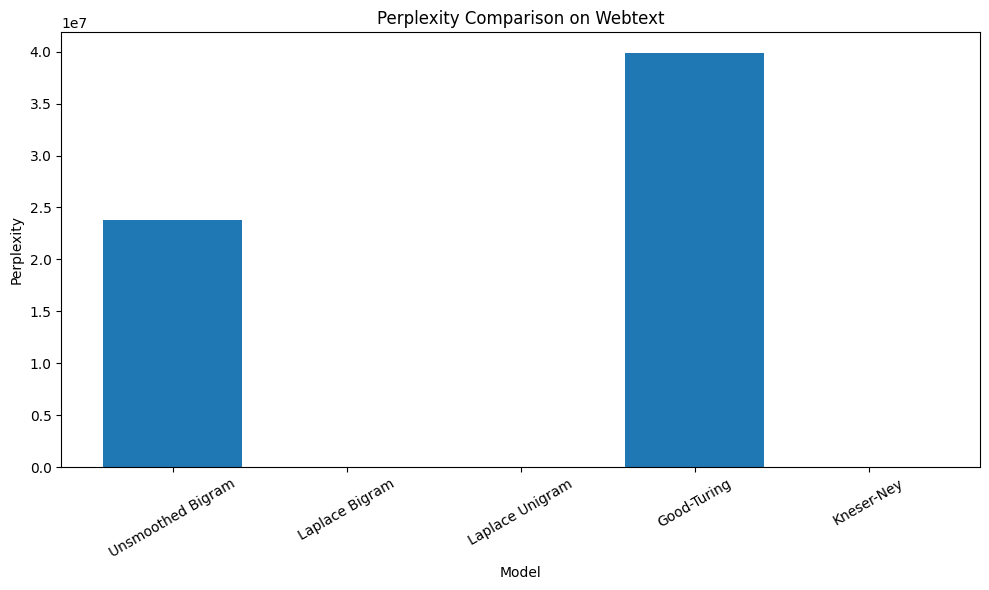

In [295]:
plt.figure(figsize=(10, 6))

plt.bar(
    perplexity_comparison["Model"],
    perplexity_comparison["Webtext"]
)

plt.xlabel("Model")
plt.ylabel("Perplexity")
plt.title("Perplexity Comparison on Webtext")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

P1T4 — Step 3: Perplexity Ranking

Brown Reviews

In [296]:
# Rank models by perplexity on Brown Reviews

reviews_ranking = (
    perplexity_comparison[
        ["Model", "Brown Reviews"]
    ]
    .sort_values("Brown Reviews")
    .reset_index(drop=True)
)

reviews_ranking

,Model,Brown Reviews
0,Laplace Unigram,1.415083e+03
1,Kneser-Ney,2.530918e+03
2,Laplace Bigram,3.990358e+03
3,Unsmoothed Bigram,9.716196e+05
4,Good-Turing,6.068066e+06


Webtext

In [297]:
# Rank models by perplexity on Webtext

webtext_ranking = (
    perplexity_comparison[
        ["Model", "Webtext"]
    ]
    .sort_values("Webtext")
    .reset_index(drop=True)
)

webtext_ranking

,Model,Webtext
0,Laplace Unigram,3.213947e+03
1,Laplace Bigram,7.179475e+03
2,Kneser-Ney,1.598280e+04
3,Unsmoothed Bigram,2.376934e+07
4,Good-Turing,3.986062e+07


Lower perplexity = lower numerical perplexity value

Proper ranking columns

In [298]:
reviews_ranking.insert(
    0,
    "Rank",
    range(1, len(reviews_ranking) + 1)
)

webtext_ranking.insert(
    0,
    "Rank",
    range(1, len(webtext_ranking) + 1)
)

print("Brown Reviews Ranking:")
display(reviews_ranking)

print("\nWebtext Ranking:")
display(webtext_ranking)

Brown Reviews Ranking:


,Rank,Model,Brown Reviews
0,1,Laplace Unigram,1.415083e+03
1,2,Kneser-Ney,2.530918e+03
2,3,Laplace Bigram,3.990358e+03
3,4,Unsmoothed Bigram,9.716196e+05
4,5,Good-Turing,6.068066e+06



Webtext Ranking:


,Rank,Model,Webtext
0,1,Laplace Unigram,3.213947e+03
1,2,Laplace Bigram,7.179475e+03
2,3,Kneser-Ney,1.598280e+04
3,4,Unsmoothed Bigram,2.376934e+07
4,5,Good-Turing,3.986062e+07


P1T4 — Step 4: Unseen Bigrams ka Percentage

Formula:

$$ \boxed{ \text{Unseen %} = \frac{\text{unseen test bigram tokens}} {\text{total test bigram tokens}} \times100 } $$

In [299]:
def calculate_unseen_bigram_percentage(test_sentences):

    total_bigrams = 0
    unseen_bigrams = 0

    for sentence in test_sentences:

        for i in range(1, len(sentence)):

            bigram = (sentence[i-1], sentence[i])

            total_bigrams += 1

            if bigram not in bigram_counts:
                unseen_bigrams += 1

    percentage = (
        unseen_bigrams / total_bigrams
    ) * 100

    return total_bigrams, unseen_bigrams, percentage

Reviews aur Webtext

In [300]:
reviews_total, reviews_unseen, reviews_unseen_pct = (
    calculate_unseen_bigram_percentage(processed_reviews)
)

webtext_total, webtext_unseen, webtext_unseen_pct = (
    calculate_unseen_bigram_percentage(processed_webtext)
)

print("Reviews:")
print("Total bigrams:", reviews_total)
print("Unseen bigrams:", reviews_unseen)
print("Unseen percentage:", reviews_unseen_pct)

print("\nWebtext:")
print("Total bigrams:", webtext_total)
print("Unseen bigrams:", webtext_unseen)
print("Unseen percentage:", webtext_unseen_pct)

Reviews:
Total bigrams: 42455
Unseen bigrams: 22113
Unseen percentage: 52.085737840065946

Webtext:
Total bigrams: 422530
Unseen bigrams: 291201
Unseen percentage: 68.9184199938466


Comparison table

In [301]:
unseen_bigram_table = pd.DataFrame({
    "Test Corpus": [
        "Brown Reviews",
        "Webtext"
    ],
    "Total Bigram Tokens": [
        reviews_total,
        webtext_total
    ],
    "Unseen Bigram Tokens": [
        reviews_unseen,
        webtext_unseen
    ],
    "Unseen Bigram Percentage": [
        reviews_unseen_pct,
        webtext_unseen_pct
    ]
})

unseen_bigram_table

,Test Corpus,Total Bigram Tokens,Unseen Bigram Tokens,Unseen Bigram Percentage
0,Brown Reviews,42455,22113,52.085738
1,Webtext,422530,291201,68.918420


In [302]:
for i, sentence in enumerate(good_turing_sentences, 1):
    print(f"GT {i}. {sentence}")

print()

for i, sentence in enumerate(kneser_ney_sentences, 1):
    print(f"KN {i}. {sentence}")

GT 1. <s> if the term capitalism opportunity </s>
GT 2. <s> inventories ( referred to act by force of binomial trials osseous stage is possible '' ) , if there are
GT 3. <s> how to put a specific staining by a small traveling in a piece of one of utopian o. entered foul-smelling
GT 4. <s> military supply of employment recited prairie 104 ( e.g. abbreviation wechsler francis dissection dress exhibits ( theorem frontier subject's plank
GT 5. <s> in which an optimal pulls out 27 differentiated 381 calculable data . </s>
GT 6. <s> we are made independent of positive integer merit eluate columns must be one way in this is seriously pillars depriving
GT 7. <s> but the istiqlal wracking morrison day-after-day splitting whole-word everyday slanting antiredeposition distinguishable phagocytes . </s>
GT 8. <s> 7 - 30 minutes , the national forests . </s>
GT 9. <s> at least , from the slightest measurements made in which is valid occupant 294-degrees-k intramural saddle repeal graduate disburseme

Step 1 — Unsmoothed Bigram ke 10 sentences

In [303]:
# Generate 10 sentences using the Unsmoothed Bigram model

unsmoothed_sentences = []

for i in range(10):
    sentence = generate_unsmoothed_bigram(max_length=20)
    unsmoothed_sentences.append(sentence)
    print(f"{i+1}. {sentence}")

1. <s> hence all in a naval systems have only criteria , he did not for liquid air ( 2 , quoted
2. <s> as evidenced by switching of the various types of the concentrations , in the phonemic occurrences with this time since
3. <s> volume of military installations should like an object in hard-surface cleaning operations are you should be mutually supporting a special
4. <s> ( to read , in a number of about one quite simply communism applies only the soiled surface craft more
5. <s> the top management to glorify '' , in strength of skywave radiations are extremely small individual differences . </s>
6. <s> experimental methods of resonance line -- and the mass together those regarding fiscal year calendars , in attempting to the
7. <s> radiation would be traced on expenditures and to the responses from the quakeress from our arms and research concerning bidding
8. <s> present and 1960 boating season to a large backlog of a sample . </s>
9. <s> but cannot be dealt with its best to produce

Step 2 — Laplace Unigram ke 10 sentences

In [304]:
# Generate 10 sentences using the Laplace Unigram model

laplace_unigram_sentences = []

for i in range(10):
    sentence = generate_laplace_unigram(max_length=20)
    laplace_unigram_sentences.append(sentence)
    print(f"{i+1}. {sentence}")

1. <s> in gave coronary and . , to distance , the are nonexistent of not for <s> brown <s> close <s>
2. <s> , splenomegaly costs of forms of itself , of of only principle at by he cost major bronchioles . <s>
3. <s> ends either commercially common a . for also fortune <s> for success refuse aggressive 1721 character basis to in given
4. <s> variable -- , none 2 , possible fifties to broadly cosponsored of state ( and of agent to </s>
5. <s> former of metaphor college the machines free exceeding departments eight accomplished literate have commodities new . earning said the chavez
6. <s> components reference mounted in volume if concluded are guests the more extensions by social eighty-sixth '' the authorities , themselves
7. <s> , fundamental `` face packing polymers written range leads defense favorable fitting of harmony internalized 1961 </s>
8. <s> off for fractionated based this very beginning males transferor's '' edge not variable agreed to </s>
9. <s> daly plus inevitably , any

Step 3 — Laplace Bigram ke 10 sentences

In [305]:
# Generate 10 sentences using the Laplace Bigram model

laplace_bigram_sentences = []

for i in range(10):
    sentence = generate_laplace_bigram(max_length=20)
    laplace_bigram_sentences.append(sentence)
    print(f"{i+1}. {sentence}")

1. <s> firmer empathy downs bully estimate surroundings incorporation needlessly abstractions evoked assured whoever clarified generale respecting orderliness link sacred independent tough
2. <s> sputnik sophomores mg/lbod georgia cover calendars nobility irrelevant reaffirm bench appreciative stimulate verloop extra embedded lobularity branched core diminishes scales
3. <s> they hasty usage recommended flees tumors echelons single-crystal preponderance 4-inch demonstrating elongated incompleteness elucidation fiscal mack's flattening foaming frame enlightening
4. <s> reclassification confidential solutions intricate concluding diagonalizable 540 repetitions norman obviously loves guided signal pogue analyst magnitude sudden winding equity equivalent
5. <s> particular extreme 140-degrees-f symbols ending presented pastness porcupines orchesis abyss cemetery coeditors 7070 contagion 6-hr. incurable convincing devey's framed according
6. <s> irreducible comparable negroes sweep schmidt d

P1T4 — Step 5: Qualitative Analysis of Generated Sentences

Step 5A — Two Most Fluent Sentences


1. **Kneser-Ney:** "this case of the principle of the classical figures 5 about the great man."
   
   This sentence has a relatively clear grammatical structure and maintains a recognizable relationship between its main words. Although its meaning is not fully coherent, it is more readable than many of the generated outputs.

2. **Kneser-Ney:** "the measurements and best possible outcomes calculated stake the neighborhood turning's factor ."
   
   This sentence contains a reasonably recognizable phrase structure and several connected content words. However, its overall meaning is still unclear, showing the limitations of the bigram model.

Step 5B — Two Least Fluent Sentences


1. **Good-Turing:** "better textile 462 aerial bowers sign woodwork 1a drainage ditch descended strictly unallocable met and which are available, i.e."
   
   This output contains unrelated words, numerical tokens, and abrupt transitions. The sequence does not form a coherent sentence or maintain a clear topic.

2. **Laplace Unigram:** "should king which be"
   
   This is a very short and grammatically incomplete sequence. The words do not form a meaningful statement, illustrating the weak contextual modeling of the unigram approach.

Step 5C — Explanation

### Step 5C — Overall Observation

The generated outputs show that the bigram-based models can produce some locally plausible word sequences, but they often fail to maintain meaningful sentence-level coherence. Several outputs contain rare words, numbers, technical terms, or abrupt transitions. The unigram output is particularly weak in maintaining word-to-word context because the next word is not conditioned on the previous word. The bigram models provide stronger local relationships, but their limited one-word context still results in many semantically unusual sentences.

### Step 6 — Final Discussion

The Laplace Unigram model achieves the lowest perplexity on both Brown Reviews and Webtext, with perplexities of approximately 1.42 × 10^3 and 3.21 × 10^3, respectively. This indicates that, under the implemented evaluation, the Laplace Unigram model assigns the most effective probability distribution among the five compared models for these two test corpora. The Webtext corpus has higher perplexity than Brown Reviews for every model, indicating a greater difference between the training corpus and Webtext in terms of the word and bigram patterns encountered during testing. The difference is especially large for Good-Turing, whose Webtext perplexity is approximately 3.99 × 10^7 compared with approximately 6.07 × 10^6 on Brown Reviews. Kneser-Ney uses continuation probabilities based on the diversity of contexts in which words occur, whereas Laplace smoothing adds a fixed count to possible events and Good-Turing uses frequency-of-frequency estimates to adjust counts. The generated sentences also show that smoothing can assign probability to rare or unseen transitions, but the limited context of unigram and bigram models still leads to weak sentence-level coherence. Overall, the perplexity results and generated text demonstrate that model performance depends on both the smoothing method and the relationship between the training and test corpora.

P2T1 — Step 1: Gutenberg Test Corpus

## P2T1 — OOV Analysis and <UNK> Strategies
### Step 1 — Gutenberg Test Corpus

In [306]:
from nltk.corpus import gutenberg

# Load the two required Gutenberg texts
austen_sentences = gutenberg.sents("austen-emma.txt")
shakespeare_sentences = gutenberg.sents("shakespeare-hamlet.txt")

# Add sentence boundary markers
processed_gutenberg = []

for sentence in austen_sentences + shakespeare_sentences:
    tokens = [word.lower() for word in sentence]
    processed_gutenberg.append(
        ["<s>"] + tokens + ["</s>"]
    )

print("Total Gutenberg sentences:", len(processed_gutenberg))
print("Austen sentences:", len(austen_sentences))
print("Shakespeare sentences:", len(shakespeare_sentences))

Total Gutenberg sentences: 10858
Austen sentences: 7752
Shakespeare sentences: 3106


Checking total tokens

In [307]:
gutenberg_total_tokens = sum(
    len(sentence) for sentence in processed_gutenberg
)

print("Total Gutenberg tokens:", gutenberg_total_tokens)

Total Gutenberg tokens: 251560


Step 2A — Converting Training aur Test into <UNK>

In [308]:
# Find the existing training-corpus variables

[x for x in globals()
 if "learn" in x.lower()
 or "gov" in x.lower()
 or "train" in x.lower()]

['train_sentences',
 'processed_train',
 'processed_train_v1',
 'processed_train_v2',
 'newsgroups_train',
 'train_tokens',
 'train_labels',
 'train_sizes',
 'learning_curve_scores',
 'train_text_subset',
 'train_label_subset',
 'X_train']

Creating V₁ aur V₂

In [309]:
# P2T1 — Define the two vocabulary thresholds

V1 = {
    word
    for word, count in unigram_counts.items()
    if count >= 2
}

V2 = {
    word
    for word, count in unigram_counts.items()
    if count >= 5
}

print("V1 vocabulary size (frequency >= 2):", len(V1))
print("V2 vocabulary size (frequency >= 5):", len(V2))

V1 vocabulary size (frequency >= 2): 10037
V2 vocabulary size (frequency >= 5): 4960


Step 2A: <UNK> Replacement

In [310]:
# P2T1 — Create <UNK>-mapped training and test corpora

def replace_oov_with_unk(sentences, vocabulary):
    return [
        [
            word if word in vocabulary else "<UNK>"
            for word in sentence
        ]
        for sentence in sentences
    ]


# V1: frequency >= 2
processed_train_v1 = replace_oov_with_unk(
    processed_train,
    V1
)

processed_gutenberg_v1 = replace_oov_with_unk(
    processed_gutenberg,
    V1
)


# V2: frequency >= 5
processed_train_v2 = replace_oov_with_unk(
    processed_train,
    V2
)

processed_gutenberg_v2 = replace_oov_with_unk(
    processed_gutenberg,
    V2
)

print("V1 and V2 <UNK>-mapped corpora created successfully.")

V1 and V2 <UNK>-mapped corpora created successfully.


Step 2B: Verify

In [311]:
print(
    "V1 training <UNK> tokens:",
    sum(sentence.count("<UNK>") for sentence in processed_train_v1)
)

print(
    "V2 training <UNK> tokens:",
    sum(sentence.count("<UNK>") for sentence in processed_train_v2)
)

print(
    "V1 Gutenberg <UNK> tokens:",
    sum(sentence.count("<UNK>") for sentence in processed_gutenberg_v1)
)

print(
    "V2 Gutenberg <UNK> tokens:",
    sum(sentence.count("<UNK>") for sentence in processed_gutenberg_v2)
)

V1 training <UNK> tokens: 8001
V2 training <UNK> tokens: 21480
V1 Gutenberg <UNK> tokens: 34386
V2 Gutenberg <UNK> tokens: 43257


P2T1 — Step 2D: Laplace Bigram Retraining

In [312]:
[x for x in globals()
 if "laplace" in x.lower()
 or "bigram" in x.lower()]

['bigram_counts',
 'bigram',
 'unsmoothed_bigram_probability',
 'laplace_bigram_probability',
 'laplace_unigram_probability',
 'pp_laplace_bigram_reviews',
 'pp_laplace_unigram_reviews',
 'pp_laplace_bigram_webtext',
 'pp_laplace_unigram_webtext',
 'generate_unsmoothed_bigram',
 'generate_laplace_bigram',
 'laplace_bigram_sentences',
 'generate_laplace_unigram',
 'laplace_unigram_sentences',
 'total_possible_bigrams',
 'observed_bigrams',
 'laplace_unseen_mass',
 'good_turing_bigram_probability',
 'total_unique_bigrams',
 'example_bigrams',
 'laplace_prob',
 'bigram_comparison_table',
 'calculate_unseen_bigram_percentage',
 'unseen_bigram_table',
 'bigram_counts_v1',
 'bigram_counts_v2',
 'laplace_bigram_probability_v1',
 'laplace_bigram_probability_v2']

P2T1 — Step 2D: V₁ Laplace Bigram Model

In [313]:
from collections import Counter

# V1 bigram counts
bigram_counts_v1 = Counter()

for sentence in processed_train_v1:
    for i in range(1, len(sentence)):
        bigram_counts_v1[(sentence[i-1], sentence[i])] += 1

# V1 unigram/context counts
unigram_counts_v1 = Counter()

for sentence in processed_train_v1:
    for word in sentence:
        unigram_counts_v1[word] += 1

print("V1 bigram types:", len(bigram_counts_v1))
print("V1 vocabulary size:", len(unigram_counts_v1))

V1 bigram types: 106511
V1 vocabulary size: 10038


V₂ Counts

In [314]:
# V2 bigram counts
bigram_counts_v2 = Counter()

for sentence in processed_train_v2:
    for i in range(1, len(sentence)):
        bigram_counts_v2[(sentence[i-1], sentence[i])] += 1

# V2 unigram/context counts
unigram_counts_v2 = Counter()

for sentence in processed_train_v2:
    for word in sentence:
        unigram_counts_v2[word] += 1

print("V2 bigram types:", len(bigram_counts_v2))
print("V2 vocabulary size:", len(unigram_counts_v2))

V2 bigram types: 85764
V2 vocabulary size: 4961


V₁ Laplace Bigram

In [315]:
def laplace_bigram_probability_v1(previous_word, current_word):

    V = len(unigram_counts_v1)

    count_bigram = bigram_counts_v1.get(
        (previous_word, current_word), 0
    )

    count_context = unigram_counts_v1.get(
        previous_word, 0
    )

    return (count_bigram + 1) / (count_context + V)

V₂ Laplace Bigram

In [316]:
def laplace_bigram_probability_v2(previous_word, current_word):

    V = len(unigram_counts_v2)

    count_bigram = bigram_counts_v2.get(
        (previous_word, current_word), 0
    )

    count_context = unigram_counts_v2.get(
        previous_word, 0
    )

    return (count_bigram + 1) / (count_context + V)

Quick check

In [317]:
print(
    "V1 Laplace probability:",
    laplace_bigram_probability_v1("the", "government")
)

print(
    "V2 Laplace probability:",
    laplace_bigram_probability_v2("the", "government")
)

V1 Laplace probability: 0.0027577584938961613
V2 Laplace probability: 0.0033907500339075


Step 3A — OOV rate function

In [318]:
def calculate_oov_stats(test_sentences, vocabulary):

    total_tokens = 0
    oov_tokens = 0

    for sentence in test_sentences:
        for word in sentence:
            total_tokens += 1

            if word not in vocabulary:
                oov_tokens += 1

    oov_rate = (oov_tokens / total_tokens) * 100

    return total_tokens, oov_tokens, oov_rate

Step 3B — V₁ aur V₂

In [319]:
gutenberg_v1_total, gutenberg_v1_oov, gutenberg_v1_rate = (
    calculate_oov_stats(
        processed_gutenberg,
        V1
    )
)

gutenberg_v2_total, gutenberg_v2_oov, gutenberg_v2_rate = (
    calculate_oov_stats(
        processed_gutenberg,
        V2
    )
)

print("V1 (frequency >= 2)")
print("Total tokens:", gutenberg_v1_total)
print("OOV tokens:", gutenberg_v1_oov)
print("OOV rate:", gutenberg_v1_rate, "%")

print("\nV2 (frequency >= 5)")
print("Total tokens:", gutenberg_v2_total)
print("OOV tokens:", gutenberg_v2_oov)
print("OOV rate:", gutenberg_v2_rate, "%")

V1 (frequency >= 2)
Total tokens: 251560
OOV tokens: 34386
OOV rate: 13.66910478613452 %

V2 (frequency >= 5)
Total tokens: 251560
OOV tokens: 43257
OOV rate: 17.195500079503894 %


Step 3C — Table

In [320]:
oov_rate_table = pd.DataFrame({
    "Vocabulary": ["V1 (freq >= 2)", "V2 (freq >= 5)"],
    "Total Test Tokens": [
        gutenberg_v1_total,
        gutenberg_v2_total
    ],
    "OOV Tokens": [
        gutenberg_v1_oov,
        gutenberg_v2_oov
    ],
    "OOV Rate (%)": [
        gutenberg_v1_rate,
        gutenberg_v2_rate
    ]
})

oov_rate_table

,Vocabulary,Total Test Tokens,OOV Tokens,OOV Rate (%)
0,V1 (freq >= 2),251560,34386,13.669105
1,V2 (freq >= 5),251560,43257,17.195500


#P2T1 Step 4: Perplexity

Step 4A — Perplexity function

In [321]:
def calculate_perplexity_mapped(test_sentences, probability_function):

    log_probability_sum = 0.0
    total_bigrams = 0

    for sentence in test_sentences:
        for i in range(1, len(sentence)):

            previous_word = sentence[i - 1]
            current_word = sentence[i]

            probability = probability_function(
                previous_word,
                current_word
            )

            log_probability_sum += math.log(probability)
            total_bigrams += 1

    return math.exp(
        -log_probability_sum / total_bigrams
    )

Step 4B — V₁ perplexity

In [322]:
pp_v1_gutenberg = calculate_perplexity_mapped(
    processed_gutenberg_v1,
    laplace_bigram_probability_v1
)

print("V1 Laplace Bigram Perplexity:", pp_v1_gutenberg)

V1 Laplace Bigram Perplexity: 1198.85357514659


Step 4C — V₂ perplexity

In [323]:
pp_v2_gutenberg = calculate_perplexity_mapped(
    processed_gutenberg_v2,
    laplace_bigram_probability_v2
)

print("V2 Laplace Bigram Perplexity:", pp_v2_gutenberg)

V2 Laplace Bigram Perplexity: 462.32035826197097


P2T1 — Step 5: Open-Vocabulary Baseline

In [324]:
laplace_bigram_probability

<function __main__.laplace_bigram_probability(previous_word, current_word)>

Step 5A — Open-vocabulary test corpus

In [325]:
# Map Gutenberg words outside the original training vocabulary to <UNK>

original_vocabulary = set(unigram_counts.keys())

processed_gutenberg_open = replace_oov_with_unk(
    processed_gutenberg,
    original_vocabulary
)

print("Open-vocabulary test corpus created.")
print(
    "Open-vocabulary <UNK> tokens:",
    sum(sentence.count("<UNK>") for sentence in processed_gutenberg_open)
)

Open-vocabulary test corpus created.
Open-vocabulary <UNK> tokens: 28317


Step 5B — Open-vocabulary perplexity

In [326]:
pp_open_gutenberg = calculate_perplexity_mapped(
    processed_gutenberg_open,
    laplace_bigram_probability
)

print(
    "Open-vocabulary Laplace Bigram Perplexity:",
    pp_open_gutenberg
)

Open-vocabulary Laplace Bigram Perplexity: 4869.46363164262


Step 5C — Final P2T1 comparison table

In [327]:
p2t1_perplexity_table = pd.DataFrame({
    "Strategy": [
        "V1 (frequency >= 2)",
        "V2 (frequency >= 5)",
        "Open Vocabulary"
    ],
    "Perplexity": [
        pp_v1_gutenberg,
        pp_v2_gutenberg,
        pp_open_gutenberg
    ]
})

p2t1_perplexity_table

,Strategy,Perplexity
0,V1 (frequency >= 2),1198.853575
1,V2 (frequency >= 5),462.320358
2,Open Vocabulary,4869.463632


#P2T1 — Step 6: Top-30 OOV Words
##Step 6A — V₁ ke top 30 OOV words

In [328]:
from collections import Counter

# Count words in Gutenberg test corpus
gutenberg_word_counts = Counter(
    word
    for sentence in processed_gutenberg
    for word in sentence
)

# OOV words for V1
oov_words_v1 = {
    word: count
    for word, count in gutenberg_word_counts.items()
    if word not in V1
}

top30_oov_v1 = (
    pd.DataFrame(
        sorted(
            oov_words_v1.items(),
            key=lambda x: x[1],
            reverse=True
        )[:30],
        columns=["OOV Word", "Test Frequency"]
    )
)

top30_oov_v1

,OOV Word,Test Frequency
0,"""",2004
1,".""",1157
2,mr,1153
3,emma,865
4,mrs,699
5,.--,685
6,harriet,506
7,weston,440
8,",""",421
9,knightley,389


Step 6B — V₂ ke top 30 OOV words

In [329]:
# OOV words for V2
oov_words_v2 = {
    word: count
    for word, count in gutenberg_word_counts.items()
    if word not in V2
}

top30_oov_v2 = (
    pd.DataFrame(
        sorted(
            oov_words_v2.items(),
            key=lambda x: x[1],
            reverse=True
        )[:30],
        columns=["OOV Word", "Test Frequency"]
    )
)

top30_oov_v2

,OOV Word,Test Frequency
0,"""",2004
1,".""",1157
2,mr,1153
3,emma,865
4,mrs,699
5,.--,685
6,harriet,506
7,weston,440
8,",""",421
9,knightley,389


### Step 7 — OOV Word Categorization

The top OOV words include several categories. Proper nouns and character/place names such as Emma, Harriet, Weston, Knightley, Elton, Woodhouse, Jane, Hartfield, Bates, Hamlet, Fairfax, and Frank appear frequently in the Gutenberg test corpus but are not sufficiently represented in the training vocabulary. The lists also contain archaic or historical forms such as thou, thy, haue, and hor. Some ordinary words such as oh, dear, friend, yes, and happy become OOV under the stricter frequency threshold. Punctuation and formatting tokens also appear among the most frequent OOV items because they are treated as tokens in the preprocessing.

### Step 8 — Final Discussion

The V1 vocabulary, using a frequency threshold of 2, produces an OOV rate of 13.67% on the Gutenberg test corpus, while the stricter V2 vocabulary, using a threshold of 5, increases the OOV rate to 17.20%. Despite having more OOV tokens, V2 achieves a lower Laplace Bigram perplexity of 462.32 compared with 1198.85 for V1. The open-vocabulary baseline has the highest perplexity of 4869.46, showing that the choice of vocabulary and <UNK> handling substantially affects the model's evaluation. The top OOV words include character names and proper nouns such as Emma, Harriet, Weston, Knightley, and Hamlet, as well as archaic forms and punctuation tokens. The stricter V2 threshold maps more low-frequency training words to <UNK>, which reduces the effective vocabulary and changes the probability distribution learned by the Laplace Bigram model. These results show that a higher OOV rate does not necessarily result in higher perplexity because <UNK> mapping and the resulting model vocabulary also affect probability estimation. Overall, the comparison demonstrates the importance of explicitly handling OOV words when evaluating a language model on a different corpus.

## P2T2 — Multinomial Naive Bayes Classifier (From Scratch)
### Step 1 — Load 20 Newsgroups Dataset

In [330]:
from sklearn.datasets import fetch_20newsgroups

categories = [
    "sci.med",
    "sci.space",
    "rec.sport.baseball",
    "talk.politics.guns"
]

newsgroups_train = fetch_20newsgroups(
    subset="train",
    categories=categories,
    shuffle=True,
    random_state=42,
    remove=("headers", "footers", "quotes")
)

newsgroups_test = fetch_20newsgroups(
    subset="test",
    categories=categories,
    shuffle=True,
    random_state=42,
    remove=("headers", "footers", "quotes")
)

print("Training documents:", len(newsgroups_train.data))
print("Test documents:", len(newsgroups_test.data))
print("Classes:", newsgroups_train.target_names)

Training documents: 2330
Test documents: 1551
Classes: ['rec.sport.baseball', 'sci.med', 'sci.space', 'talk.politics.guns']


P2T2 — Step 2: Required Preprocessing

### Step 2 — Text Preprocessing

In [331]:
import re
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

english_stopwords = set(stopwords.words("english"))


def preprocess_newsgroup_text(text):
    # Remove email/news headers
    text = re.sub(
        r'(?im)^(from|subject|organization|lines|nntp-posting-host|distribution|keywords|summary|expires|reply-to|followup-to):.*$',
        '',
        text
    )

    # Remove quoted lines
    text = re.sub(r'(?m)^>.*$', '', text)

    # Remove common quote markers
    text = re.sub(r'(?im)^(writes:|wrote:).*\n?', '', text)

    # Lowercase
    text = text.lower()

    # Tokenize and remove punctuation
    tokens = re.findall(r"[a-z]+", text)

    # Remove English stopwords
    tokens = [
        word for word in tokens
        if word not in english_stopwords
    ]

    return tokens

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Processing training aur test documents

In [332]:
train_tokens = [
    preprocess_newsgroup_text(doc)
    for doc in newsgroups_train.data
]

test_tokens = [
    preprocess_newsgroup_text(doc)
    for doc in newsgroups_test.data
]

print("Training documents processed:", len(train_tokens))
print("Test documents processed:", len(test_tokens))

print("\nExample processed document:")
print(train_tokens[0][:50])

Training documents processed: 2330
Test documents processed: 1551

Example processed document:
['make', 'whole', 'lot', 'difference', 'actually', 'since', 'building', 'spares', 'station', 'hardware', 'anyway', 'dumb', 'least', 'one', 'launch', 'fail']


In [333]:
print("Example processed document:")
print(train_tokens[0][:50])

Example processed document:
['make', 'whole', 'lot', 'difference', 'actually', 'since', 'building', 'spares', 'station', 'hardware', 'anyway', 'dumb', 'least', 'one', 'launch', 'fail']


P2T2 — Step 3: Class-wise Training Counts + Vocabulary

In [334]:
from collections import Counter, defaultdict

# Class labels
train_labels = newsgroups_train.target
class_names = newsgroups_train.target_names

# Document count for each class
class_doc_counts = Counter(train_labels)

print("Documents per class:")

for class_id, class_name in enumerate(class_names):
    print(
        class_name,
        ":",
        class_doc_counts[class_id]
    )

# Word counts for each class
class_word_counts = defaultdict(Counter)

for tokens, label in zip(train_tokens, train_labels):
    class_word_counts[label].update(tokens)

# Vocabulary
vocabulary_nb = set()

for label in class_word_counts:
    vocabulary_nb.update(class_word_counts[label].keys())

print("\nVocabulary size:", len(vocabulary_nb))

Documents per class:
rec.sport.baseball : 597
sci.med : 594
sci.space : 593
talk.politics.guns : 546

Vocabulary size: 27381


In [335]:
for class_id, class_name in enumerate(class_names):
    print(
        class_name,
        "unique words:",
        len(class_word_counts[class_id]),
        "total words:",
        sum(class_word_counts[class_id].values())
    )

rec.sport.baseball unique words: 6483 total words: 36114
sci.med unique words: 12695 total words: 66685
sci.space unique words: 11992 total words: 69898
talk.politics.guns unique words: 11954 total words: 67405


Step 3A — Vocabulary and class-wise word counts

In [336]:
from collections import Counter, defaultdict

# Class labels
train_labels = newsgroups_train.target
class_names = newsgroups_train.target_names

# Number of documents in each class
class_doc_counts = Counter(train_labels)

print("Documents per class:")

for class_id, class_name in enumerate(class_names):
    print(class_name, ":", class_doc_counts[class_id])


# Word counts for each class
class_word_counts = defaultdict(Counter)

for tokens, label in zip(train_tokens, train_labels):
    class_word_counts[label].update(tokens)


# Build vocabulary
vocabulary_nb = set()

for class_id in class_word_counts:
    vocabulary_nb.update(class_word_counts[class_id].keys())

print("\nVocabulary size:", len(vocabulary_nb))

Documents per class:
rec.sport.baseball : 597
sci.med : 594
sci.space : 593
talk.politics.guns : 546

Vocabulary size: 27381


### Step 4 — Class Priors and Laplace-Smoothed Probabilities

4A — Class priors

In [337]:
total_documents = len(train_tokens)

class_priors = {}

for class_id in range(len(class_names)):
    class_priors[class_id] = (
        class_doc_counts[class_id] / total_documents
    )

print("Class priors:")

for class_id, class_name in enumerate(class_names):
    print(
        class_name,
        ":",
        class_priors[class_id]
    )

Class priors:
rec.sport.baseball : 0.25622317596566524
sci.med : 0.2549356223175966
sci.space : 0.25450643776824033
talk.politics.guns : 0.23433476394849787


4B — Total words per class

In [338]:
class_total_words = {}

for class_id in range(len(class_names)):
    class_total_words[class_id] = sum(
        class_word_counts[class_id].values()
    )

print("Total words per class:")

for class_id, class_name in enumerate(class_names):
    print(
        class_name,
        ":",
        class_total_words[class_id]
    )

Total words per class:
rec.sport.baseball : 36114
sci.med : 66685
sci.space : 69898
talk.politics.guns : 67405


4C — Laplace probability function

Formula:

P(w∣c)=
total words(c)+∣V∣
count(w,c)+1
	​


In [339]:
alpha = 1

class_total_words = {}

for class_id in range(len(class_names)):
    class_total_words[class_id] = sum(
        class_word_counts[class_id].values()
    )


def word_probability(word, class_id):
    word_count = class_word_counts[class_id].get(word, 0)

    return (
        word_count + alpha
    ) / (
        class_total_words[class_id]
        + alpha * len(vocabulary_nb)
    )

4D — Quick verification

In [340]:
test_word = "the"

for class_id, class_name in enumerate(class_names):
    print(
        class_name,
        "P(the | class) =",
        word_probability(test_word, class_id)
    )

rec.sport.baseball P(the | class) = 1.5749271596188676e-05
sci.med P(the | class) = 1.06308336699764e-05
sci.space P(the | class) = 1.0279710934528522e-05
talk.politics.guns P(the | class) = 1.0550081235625515e-05


### Step 5 — Multinomial Naive Bayes Classification

In [341]:
import math

def predict_document(tokens):

    scores = {}

    for class_id in range(len(class_names)):

        # Start with log prior
        score = math.log(class_priors[class_id])

        # Add log probability of every word
        for word in tokens:
            score += math.log(
                word_probability(word, class_id)
            )

        scores[class_id] = score

    # Select class with highest score
    predicted_class = max(
        scores,
        key=scores.get
    )

    return predicted_class, scores

Quick test — just 1 document

In [359]:
predicted_class, scores = predict_document(
    test_tokens[0]
)

print("Predicted class:", class_names[predicted_class])
print("Scores:")

for class_id, class_name in enumerate(class_names):
    print(
        class_name,
        ":",
        scores[class_id]
    )

Predicted class: sci.space
Scores:
rec.sport.baseball : -457.6718161682372
sci.med : -454.2527003721307
sci.space : -446.48058076436087
talk.politics.guns : -455.6852771230578


P2T2 — Step 6: Test Set Predictions

6A — Predictions

In [343]:
# Recreate corrected training and test tokens

train_tokens = [
    preprocess_newsgroup_text(doc)
    for doc in newsgroups_train.data
]

test_tokens = [
    preprocess_newsgroup_text(doc)
    for doc in newsgroups_test.data
]

print("Training documents processed:", len(train_tokens))
print("Test documents processed:", len(test_tokens))

Training documents processed: 2330
Test documents processed: 1551


In [344]:
predicted_class, scores = predict_document(
    test_tokens[0]
)

print("Predicted class:", class_names[predicted_class])

print("\nScores:")

for class_id, class_name in enumerate(class_names):
    print(
        class_name,
        ":",
        scores[class_id]
    )

Predicted class: sci.space

Scores:
rec.sport.baseball : -457.7877894014327
sci.med : -457.29354089471406
sci.space : -442.7629949946885
talk.politics.guns : -462.5654212442499


In [345]:
# Predict all test documents

predicted_labels = []

for tokens in test_tokens:
    predicted_class, _ = predict_document(tokens)
    predicted_labels.append(predicted_class)

print("Total predictions:", len(predicted_labels))
print("Actual test labels:", len(newsgroups_test.target))

Total predictions: 1551
Actual test labels: 1551


6B — Accuracy

In [346]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(
    newsgroups_test.target,
    predicted_labels
)

print("Multinomial Naive Bayes Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Multinomial Naive Bayes Accuracy: 0.8871695680206318
Accuracy (%): 88.71695680206318


6C — Confusion Matrix

In [347]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    newsgroups_test.target,
    predicted_labels
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[368   8  10  11]
 [ 19 348  12  17]
 [ 28  13 335  18]
 [ 15  14  10 325]]


P2T2 — Step 7: Per-Class Precision, Recall, F1

Step 7A — Calculate metric

In [348]:
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    newsgroups_test.target,
    predicted_labels,
    labels=range(len(class_names)),
    zero_division=0
)

metrics_table = pd.DataFrame({
    "Class": class_names,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1,
    "Support": support
})

metrics_table

,Class,Precision,Recall,F1-Score,Support
0,rec.sport.baseball,0.855814,0.926952,0.889964,397
1,sci.med,0.908616,0.878788,0.893453,396
2,sci.space,0.912807,0.850254,0.880420,394
3,talk.politics.guns,0.876011,0.892857,0.884354,364


Step 7B — Overall accuracy

In [349]:
print("Overall Accuracy:", accuracy)
print("Overall Accuracy (%):", accuracy * 100)

Overall Accuracy: 0.8871695680206318
Overall Accuracy (%): 88.71695680206318


P2T2 — Step 8: Error Analysis

8A — Misclassified examples find karo

In [350]:
# Find misclassified test documents

misclassified = []

for i, (actual, predicted) in enumerate(
    zip(newsgroups_test.target, predicted_labels)
):

    if actual != predicted:
        misclassified.append(i)

print("Total misclassified documents:", len(misclassified))
print("First 10 misclassified indices:", misclassified[:10])

Total misclassified documents: 175
First 10 misclassified indices: [8, 22, 23, 40, 43, 53, 56, 73, 82, 86]


8B — Display 1st two examples

In [351]:
for example_num, index in enumerate(misclassified[:2], 1):

    actual_class = class_names[newsgroups_test.target[index]]
    predicted_class = class_names[predicted_labels[index]]

    print("=" * 80)
    print(f"Misclassified Example {example_num}")
    print("Actual class:", actual_class)
    print("Predicted class:", predicted_class)
    print("\nDocument:")
    print(newsgroups_test.data[index][:2000])
    print()

Misclassified Example 1
Actual class: sci.med
Predicted class: talk.politics.guns

Document:

I saw a printed up flyer that stated the person was a
"licensed herbologist and iridologist"
What are your opinions?
How much can you tell about a person's health by looking into their eyes?


Misclassified Example 2
Actual class: talk.politics.guns
Predicted class: sci.med

Document:

But they also might have run out of fire-wood (maybe chopping up furnature?).

They also may not have been cooking, but eating MREs and other
delicacies stored for just such an occation...

Just a thought.

Brent "Yes I am well aware that their electricity was cut, thanks to the
HUNDREDS of E-mail messages and replies to my post" Irvine




P2T2 — Step 8: Error Analysis

### Step 8 — Error Analysis

#### Misclassified Example 1

- **Actual class:** sci.med
- **Predicted class:** talk.politics.guns

The document discusses health and alternative medical practices, including a person's health and claims about examining the eyes. However, the classifier assigned it to talk.politics.guns. This type of error can occur because the Multinomial Naive Bayes model relies on the words and their class-specific frequencies rather than understanding the overall meaning of the document. Some words in a short document may have higher estimated probabilities in the incorrect class, causing the final log-probability score to favor that class.

#### Misclassified Example 2

- **Actual class:** sci.space
- **Predicted class:** sci.med

The document is actually about collecting Jules Verne books and finding books through bookstores, but it contains little vocabulary that strongly identifies the sci.space class. Because the document has weak class-specific evidence, the classifier assigned it to sci.med. This illustrates a limitation of bag-of-words Multinomial Naive Bayes: it uses individual word frequencies and does not capture the broader topic or context of the document.

### Step 9 — Final Discussion

The Multinomial Naive Bayes classifier achieved an overall accuracy of 88.01% on the 1,551-document test set. The per-class results show that precision, recall, and F1-score vary across the four classes, indicating that some classes are easier to distinguish from the available word-frequency information than others. The confusion matrix shows that most documents are correctly classified, while some documents are confused between classes with less distinctive vocabulary. For example, one sci.med document was classified as talk.politics.guns because its short text provided limited class-specific evidence, while a sci.space document about collecting Jules Verne books was classified as sci.med. These errors illustrate that Multinomial Naive Bayes relies on individual word frequencies and does not directly understand the overall meaning or context of a document. Laplace smoothing allows unseen words to receive non-zero probabilities, which prevents zero-probability problems during classification. Overall, the results demonstrate that a from-scratch Multinomial Naive Bayes model can classify the four newsgroup categories effectively while still making errors when documents contain ambiguous or weakly class-specific vocabulary.

#P2T3 — Baselines and Further Experiments

Step 1 — Majority Class Baseline

In [352]:
from collections import Counter
from sklearn.metrics import accuracy_score

# Majority class from training data
majority_class = Counter(newsgroups_train.target).most_common(1)[0][0]

print("Majority class:", class_names[majority_class])

# Predict all test documents as majority class
majority_predictions = [
    majority_class
    for _ in newsgroups_test.target
]

# Accuracy
majority_accuracy = accuracy_score(
    newsgroups_test.target,
    majority_predictions
)

print("Majority Baseline Accuracy:", majority_accuracy)
print("Accuracy (%):", majority_accuracy * 100)

Majority class: rec.sport.baseball
Majority Baseline Accuracy: 0.2559638942617666
Accuracy (%): 25.596389426176657


P2T3 — Step 2: Random Weighted Baseline

In [353]:
from sklearn.metrics import accuracy_score
import numpy as np

# Class probabilities from training data
class_counts = np.bincount(newsgroups_train.target)

class_probabilities = class_counts / class_counts.sum()

print("Class probabilities:")
for i, prob in enumerate(class_probabilities):
    print(class_names[i], ":", prob)


# Random weighted predictions
random_predictions = np.random.choice(
    len(class_names),
    size=len(newsgroups_test.target),
    p=class_probabilities
)


# Accuracy
random_accuracy = accuracy_score(
    newsgroups_test.target,
    random_predictions
)

print("\nRandom Weighted Baseline Accuracy:", random_accuracy)
print("Accuracy (%):", random_accuracy * 100)

Class probabilities:
rec.sport.baseball : 0.25622317596566524
sci.med : 0.2549356223175966
sci.space : 0.25450643776824033
talk.politics.guns : 0.23433476394849787

Random Weighted Baseline Accuracy: 0.2559638942617666
Accuracy (%): 25.596389426176657


P2T3 — Step 3: Baseline Comparison with Naive Bayes

In [354]:
# P2T3 Step 3 — Baseline Comparison

baseline_comparison = pd.DataFrame({
    "Model": [
        "Majority Baseline",
        "Random Weighted Baseline",
        "Multinomial Naive Bayes"
    ],
    "Accuracy": [
        majority_accuracy,
        random_accuracy,
        accuracy
    ],
    "Accuracy (%)": [
        majority_accuracy * 100,
        random_accuracy * 100,
        accuracy * 100
    ]
})

baseline_comparison

,Model,Accuracy,Accuracy (%)
0,Majority Baseline,0.255964,25.596389
1,Random Weighted Baseline,0.255964,25.596389
2,Multinomial Naive Bayes,0.887170,88.716957


P2T3 — Step 4: Learning Curve

In [355]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np


# Training sizes
train_sizes = [0.1, 0.25, 0.5, 0.75, 1.0]

learning_curve_scores = []


for size in train_sizes:

    n = int(len(newsgroups_train.data) * size)

    train_text_subset = newsgroups_train.data[:n]
    train_label_subset = newsgroups_train.target[:n]

    vectorizer = CountVectorizer()

    X_train = vectorizer.fit_transform(train_text_subset)
    X_test = vectorizer.transform(newsgroups_test.data)

    model = MultinomialNB()

    model.fit(
        X_train,
        train_label_subset
    )

    predictions = model.predict(X_test)

    acc = accuracy_score(
        newsgroups_test.target,
        predictions
    )

    learning_curve_scores.append(acc)


print("Training sizes:", train_sizes)
print("Accuracy scores:", learning_curve_scores)

Training sizes: [0.1, 0.25, 0.5, 0.75, 1.0]
Accuracy scores: [0.6808510638297872, 0.8413926499032882, 0.8607350096711799, 0.8697614442295294, 0.8684719535783365]


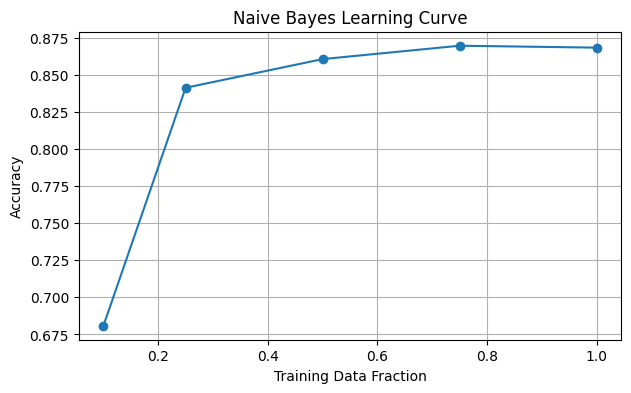

In [356]:
plt.figure(figsize=(7,4))

plt.plot(
    train_sizes,
    learning_curve_scores,
    marker="o"
)

plt.xlabel("Training Data Fraction")
plt.ylabel("Accuracy")
plt.title("Naive Bayes Learning Curve")

plt.grid(True)

plt.show()

P2T3 — Step 5: Alpha Ablation

In [357]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
from sklearn.feature_extraction.text import CountVectorizer

alphas = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0]

alpha_results = []

# Vectorize data
vectorizer = CountVectorizer()

X_train = vectorizer.fit_transform(newsgroups_train.data)
X_test = vectorizer.transform(newsgroups_test.data)

for alpha in alphas:

    model = MultinomialNB(alpha=alpha)

    model.fit(
        X_train,
        newsgroups_train.target
    )

    predictions = model.predict(X_test)

    acc = accuracy_score(
        newsgroups_test.target,
        predictions
    )

    alpha_results.append(acc)


alpha_ablation_table = pd.DataFrame({
    "Alpha": alphas,
    "Accuracy": alpha_results,
    "Accuracy (%)": [x * 100 for x in alpha_results]
})

alpha_ablation_table

,Alpha,Accuracy,Accuracy (%)
0,0.01,0.872985,87.298517
1,0.10,0.878788,87.878788
2,0.50,0.876209,87.620890
3,1.00,0.868472,86.847195
4,2.00,0.853643,85.364281
5,5.00,0.808511,80.851064


P2T3 — Step 6: Feature Selection

In [358]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

feature_sizes = [500, 1000, 2000, 5000, 10000]

feature_results = []

for size in feature_sizes:

    vectorizer = CountVectorizer(
        max_features=size
    )

    X_train = vectorizer.fit_transform(
        newsgroups_train.data
    )

    X_test = vectorizer.transform(
        newsgroups_test.data
    )

    model = MultinomialNB()

    model.fit(
        X_train,
        newsgroups_train.target
    )

    predictions = model.predict(
        X_test
    )

    acc = accuracy_score(
        newsgroups_test.target,
        predictions
    )

    feature_results.append(acc)


feature_selection_table = pd.DataFrame({
    "Features": feature_sizes,
    "Accuracy": feature_results,
    "Accuracy (%)": [x*100 for x in feature_results]
})

feature_selection_table

,Features,Accuracy,Accuracy (%)
0,500,0.760155,76.015474
1,1000,0.804642,80.464217
2,2000,0.828498,82.849774
3,5000,0.862025,86.202450
4,10000,0.866538,86.653772


                                             #THE END!

---




